BMTC GTFS ANALYSIS

In [ ]:
import os
import shutil
from google.colab import drive

# Forcibly remove the local /content/drive directory if it contains local files preventing the mount
if os.path.exists('/content/drive'):
    try:
        shutil.rmtree('/content/drive')
        print("Cleared stale local /content/drive path.")
    except Exception as e:
        print(f"Could not remove /content/drive: {e}")

# Mount Google Drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


PHASE 1

Data Preprocessing and cleaning

In [ ]:
import os

PROJECT_PATH = "/content/drive/MyDrive/BMTC_Bus_Network_Analytics"

NOTEBOOK_PATH = os.path.join(PROJECT_PATH, "notebooks")
PROCESSED_PATH = os.path.join(PROJECT_PATH, "data", "processed")
OUTPUT_PATH = os.path.join(PROJECT_PATH, "outputs")
DOCS_PATH = os.path.join(PROJECT_PATH, "documentation")

os.makedirs(NOTEBOOK_PATH, exist_ok=True)
os.makedirs(PROCESSED_PATH, exist_ok=True)
os.makedirs(OUTPUT_PATH, exist_ok=True)
os.makedirs(DOCS_PATH, exist_ok=True)

print("Project folder exists:", os.path.exists(PROJECT_PATH))
print("Notebook folder exists:", os.path.exists(NOTEBOOK_PATH))
print("Processed folder exists:", os.path.exists(PROCESSED_PATH))
print("Output folder exists:", os.path.exists(OUTPUT_PATH))
print("Documentation folder exists:", os.path.exists(DOCS_PATH))

Project folder exists: True
Notebook folder exists: True
Processed folder exists: True
Output folder exists: True
Documentation folder exists: True


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving BMTC_Original_Datasets.zip to BMTC_Original_Datasets.zip


In [ ]:
import zipfile
import os

ZIP_PATH = "/content/BMTC_Original_Datasets.zip"
EXTRACT_PATH = "/content/BMTC_Original_Datasets"

os.makedirs(EXTRACT_PATH, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_PATH)

print("Dataset extraction completed!")
print("Extraction folder exists:", os.path.exists(EXTRACT_PATH))

Dataset extraction completed!
Extraction folder exists: True


In [ ]:
for root, dirs, files_list in os.walk(EXTRACT_PATH):
    for file in sorted(files_list):
        full_path = os.path.join(root, file)
        relative_path = os.path.relpath(full_path, EXTRACT_PATH)

        size_mb = os.path.getsize(full_path) / (1024 * 1024)

        print(f"{relative_path} | {size_mb:.2f} MB")

wards_bengaluru_gba.geojson | 2.91 MB
bmtc_raw_dataset/agency.txt | 0.00 MB
bmtc_raw_dataset/calendar.txt | 0.00 MB
bmtc_raw_dataset/fare_attributes.txt | 0.00 MB
bmtc_raw_dataset/fare_rules.txt | 35.98 MB
bmtc_raw_dataset/feed_info.txt | 0.00 MB
bmtc_raw_dataset/routes.txt | 0.25 MB
bmtc_raw_dataset/shapes.txt | 98.69 MB
bmtc_raw_dataset/stop_times.txt | 74.79 MB
bmtc_raw_dataset/stops.txt | 0.82 MB
bmtc_raw_dataset/translations.txt | 1.25 MB
bmtc_raw_dataset/trips.txt | 2.46 MB


In [ ]:
gtfs_files = []
geojson_files = []

for root, dirs, files_list in os.walk(EXTRACT_PATH):
    for file in files_list:
        full_path = os.path.join(root, file)

        if file.lower().endswith(".txt"):
            gtfs_files.append(full_path)

        elif file.lower().endswith(".geojson"):
            geojson_files.append(full_path)

print("Total GTFS files:", len(gtfs_files))
print("Total GeoJSON files:", len(geojson_files))

print("\nGTFS FILES:")
for file in sorted(gtfs_files):
    print(os.path.basename(file))

print("\nWARD DATA FILES:")
for file in sorted(geojson_files):
    print(os.path.basename(file))

Total GTFS files: 11
Total GeoJSON files: 1

GTFS FILES:
agency.txt
calendar.txt
fare_attributes.txt
fare_rules.txt
feed_info.txt
routes.txt
shapes.txt
stop_times.txt
stops.txt
translations.txt
trips.txt

WARD DATA FILES:
wards_bengaluru_gba.geojson


In [ ]:
import pandas as pd
import os

gtfs_tables = {}

for file_path in gtfs_files:

    table_name = os.path.splitext(
        os.path.basename(file_path)
    )[0].lower()

    try:
        df = pd.read_csv(file_path, low_memory=False)

        gtfs_tables[table_name] = df

        print("\nTable:", table_name)
        print("Rows:", df.shape[0])
        print("Columns:", df.shape[1])
        print("Column names:", df.columns.tolist())

    except Exception as e:
        print("\nError reading:", table_name)
        print(e)


Table: agency
Rows: 1
Columns: 4
Column names: ['agency_id', 'agency_name', 'agency_url', 'agency_timezone']

Table: fare_rules
Rows: 1353440
Columns: 4
Column names: ['fare_id', 'route_id', 'origin_id', 'destination_id']

Table: translations
Rows: 9269
Columns: 5
Column names: ['table_name', 'field_name', 'record_id', 'language', 'translation']

Table: trips
Rows: 55071
Columns: 6
Column names: ['route_id', 'service_id', 'trip_headsign', 'direction_id', 'shape_id', 'trip_id']

Table: shapes
Rows: 2298668
Columns: 5
Column names: ['shape_id', 'shape_pt_lat', 'shape_pt_lon', 'shape_pt_sequence', 'shape_dist_traveled']

Table: fare_attributes
Rows: 60
Columns: 7
Column names: ['fare_id', 'price', 'currency_type', 'payment_method', 'transfers', 'transfer_duration', 'agency_id']

Table: stops
Rows: 9596
Columns: 6
Column names: ['stop_name', 'zone_id', 'stop_id', 'stop_desc', 'stop_lat', 'stop_lon']

Table: stop_times
Rows: 1486887
Columns: 6
Column names: ['trip_id', 'arrival_time', 'dep

In [ ]:
required_tables = [
    "agency",
    "routes",
    "stops",
    "trips",
    "stop_times",
    "calendar",
    "calendar_dates"
]

print("GTFS TABLE AVAILABILITY\n")

for table in required_tables:

    if table in gtfs_tables:
        print(table, "-> AVAILABLE")

    else:
        print(table, "-> NOT FOUND")

GTFS TABLE AVAILABILITY

agency -> AVAILABLE
routes -> AVAILABLE
stops -> AVAILABLE
trips -> AVAILABLE
stop_times -> AVAILABLE
calendar -> AVAILABLE
calendar_dates -> NOT FOUND


In [ ]:
#inspect routes stops and trips

if "routes" in gtfs_tables:
    routes = gtfs_tables["routes"]

    print("Total route records:", len(routes))
    display(routes.head(10))

Total route records: 4164


,route_long_name,route_short_name,agency_id,route_type,route_id
0,2nd Stage 9th Block Nagarabhavi ⇔ Shivajinagar...,244-C VSD,1,3,3447
1,5th Block HBR Layout ⇔ Kalyananagara Bus Stand,KLN-HBR,1,3,7041
2,5th Block HBR Layout ⇔ Kempegowda Bus Station,296,1,3,2712
3,5th Block HBR Layout ⇔ Kempegowda Bus Station,296-B,1,3,4821
4,5th Block HBR Layout ⇔ Shivajinagara Bus Station,296-D,1,3,2809
5,8th Mile Dasarahalli ⇔ 8th Mile Dasarahalli,BC-7C,1,3,4673
6,8th Mile Dasarahalli ⇔ 8th Mile Dasarahalli,BC-7CA,1,3,4681
7,8th Mile Dasarahalli ⇔ 8th Mile Dasarahalli Ar...,250-DD,1,3,8574
8,8th Mile Dasarahalli ⇔ Depot-31 Gate,8THM-D31G,1,3,7674
9,8th Mile Dasarahalli ⇔ Depot-31 Gate,BC-7H D31G-8MYL,1,3,5985


In [ ]:
if "stops" in gtfs_tables:
    stops = gtfs_tables["stops"]

    print("Total stop records:", len(stops))
    print("\nColumns:", stops.columns.tolist())

    display(stops.head(10))

Total stop records: 9596

Columns: ['stop_name', 'zone_id', 'stop_id', 'stop_desc', 'stop_lat', 'stop_lon']


,stop_name,zone_id,stop_id,stop_desc,stop_lat,stop_lon
0,12th Block Nagarabhavi,21629,21629,12th Block Nagarabhavi (Towards AIT College),12.96018,77.51398
1,12th Block Nagarabhavi,21630,21630,12th Block Nagarabhavi (Towards Nagarabhavi Ci...,12.96076,77.51351
2,14th Main HSR Layout,20568,20568,14th Main HSR Layout (Towards Hebbala),12.91637,77.63472
3,18th Main Jayanagara,22890,22890,18th Main Jayanagara (Towards Jayanagara 4th B...,12.92328,77.58898
4,19th Main 13th Cross HSR Layout,22891,22891,19th Main 13th Cross HSR Layout (Towards Paran...,12.91593,77.65176
5,19th Main 13th Cross HSR Layout,24300,24300,19th Main 13th Cross HSR Layout (Towards Agara...,12.91582,77.65175
6,1st Main Kodichikkanahalli,29393,29393,1st Main Kodichikkanahalli (Towards Kodichikka...,12.89854,77.61543
7,1st Main Kodichikkanahalli,35599,35599,1st Main Kodichikkanahalli (Towards Vijaya Ban...,12.89847,77.61550
8,1st Stage 3rd Block Nagarabhavi (Nayandahalli),22896,22896,1st Stage 3rd Block Nagarabhavi (Nayandahalli)...,12.95302,77.52026
9,1st Stage 3rd Block Nagarabhavi (Summanahalli),22897,22897,1st Stage 3rd Block Nagarabhavi (Summanahalli)...,12.95286,77.52017


In [ ]:
if "trips" in gtfs_tables:
    trips = gtfs_tables["trips"]

    print("Total trip records:", len(trips))
    display(trips.head(10))

Total trip records: 55071


,route_id,service_id,trip_headsign,direction_id,shape_id,trip_id
0,1000,1,Chandapura,0,KBS-3C UP,1044
1,1000,1,Chandapura,0,KBS-3C UP,1045
2,1000,1,Chandapura,0,KBS-3C UP,1046
3,1000,1,Chandapura,0,KBS-3C UP,1047
4,1000,1,Chandapura,0,KBS-3C UP,1048
5,1000,1,Chandapura,0,KBS-3C UP,1049
6,1000,1,Chandapura,0,KBS-3C UP,1050
7,1000,1,Chandapura,0,KBS-3C UP,1051
8,1000,1,Chandapura,0,KBS-3C UP,1052
9,1000,1,Chandapura,0,KBS-3C UP,1053


In [ ]:
if "stop_times" in gtfs_tables:
    stop_times = gtfs_tables["stop_times"]

    print("Total stop-time records:", len(stop_times))
    display(stop_times.head(10))

Total stop-time records: 1486887


,trip_id,arrival_time,departure_time,stop_id,stop_sequence,stop_headsign
0,34162,17:45:00,17:45:00,27263,1,2nd Stage 9th Block Nagarabhavi
1,34162,17:47:13,17:47:13,20985,2,2nd Stage 9th Block Nagarabhavi
2,34162,17:54:57,17:54:57,20921,3,2nd Stage 9th Block Nagarabhavi
3,34162,17:58:21,17:58:21,35387,4,2nd Stage 9th Block Nagarabhavi
4,34162,18:01:34,18:01:34,21200,5,2nd Stage 9th Block Nagarabhavi
5,34162,18:04:01,18:04:01,35429,6,2nd Stage 9th Block Nagarabhavi
6,34162,18:06:33,18:06:33,20587,7,2nd Stage 9th Block Nagarabhavi
7,34162,18:10:01,18:10:01,21101,8,2nd Stage 9th Block Nagarabhavi
8,34162,18:10:49,18:10:49,28613,9,2nd Stage 9th Block Nagarabhavi
9,34162,18:16:25,18:16:25,20600,10,2nd Stage 9th Block Nagarabhavi


In [ ]:
#load and inspect the ward geojson

!pip -q install geopandas

In [ ]:
import geopandas as gpd
import os

if len(geojson_files) == 1:

    ward_file = geojson_files[0]

    wards = gpd.read_file(ward_file)

    print("Ward file:", os.path.basename(ward_file))
    print("Dataset shape:", wards.shape)

    print("\nColumn names:")
    print(wards.columns.tolist())

    print("\nCoordinate reference system:")
    print(wards.crs)

    display(wards.head())

elif len(geojson_files) == 0:

    print("No GeoJSON file found.")

else:

    print("Multiple GeoJSON files found. We need to select the correct file.")
    print(geojson_files)

Ward file: wards_bengaluru_gba.geojson
Dataset shape: (369, 32)

Column names:
['tessellate', 'extrude', 'visibility', 'id2', 'Corporation', 'corporation_kn', 'corporation_id', 'ac', 'ac_kn', 'ac_no', 'Assembly', 'ward_id', 'ward_name', 'ward_name_kn', 'TOT_P', 'TOT_M', 'TOT_F', 'SC_P', 'SC_M', 'SC_F', 'ST_P', 'ST_M', 'ST_F', 'low_range', 'high_range', 'RO_Code', 'RO_Division', 'ARO_Code', 'ARO_ Sub Division', 'zone', 'zone_name', 'geometry']

Coordinate reference system:
EPSG:4326


,tessellate,extrude,visibility,id2,Corporation,corporation_kn,corporation_id,ac,ac_kn,ac_no,...,ST_F,low_range,high_range,RO_Code,RO_Division,ARO_Code,ARO_ Sub Division,zone,zone_name,geometry
0,-1,0,-1,ward_369_final.1,West,ಪಶ್ಚಿಮ,5,Rajarajeshwarinagar,ರಾಜರಾಜೇಶ್ವರಿನಗರ,154,...,201.0,18949,28424,11,RO- Rajarajeswari Nagara,34,ARO- Jnana Bharathi,Zone1,Rajarajeshwarinagar,"POLYGON ((77.51174 12.9554, 77.5118 12.95542, ..."
1,-1,0,-1,ward_369_final.2,North,ಉತ್ತರ,2,Yelahanka,ಯಲಹಂಕ,150,...,270.0,19943,29914,11,RO- Yelahanka,29,ARO- Yelahanka Old Town,Zone2,Yelahanka,"MULTIPOLYGON (((77.62561 13.10441, 77.62556 13..."
2,-1,0,-1,ward_369_final.3,North,ಉತ್ತರ,2,Yelahanka,ಯಲಹಂಕ,150,...,213.0,19943,29914,11,RO- Yelahanka,29,ARO- Yelahanka Old Town,Zone2,Yelahanka,"POLYGON ((77.56668 13.11875, 77.56819 13.11859..."
3,-1,0,-1,ward_369_final.17,East,ಪೂರ್ವ,3,K.R. Pura,ಕೆ.ಆರ್. ಪುರ,151,...,161.0,14567,21851,3,RO- Ramamurthy Nagara,8,ARO- Ramamurthy Nagara,Zone2,K.R. Pura,"POLYGON ((77.67055 13.01757, 77.67061 13.01734..."
4,-1,0,-1,ward_369_final.4,North,ಉತ್ತರ,2,Hebbal,ಹೆಬ್ಬಾಳ,158,...,187.0,19943,29914,4,RO- Hebbal,11,ARO- Nagashettyhalli,Zone2,Yelahanka,"POLYGON ((77.56897 13.03653, 77.56902 13.03604..."


In [ ]:
#check ward data quality

print("TOTAL WARD RECORDS:", len(wards))

print("\nMissing values:")
print(wards.isnull().sum())

print("\nEmpty geometries:")
print(wards.geometry.is_empty.sum())

print("\nInvalid geometries:")
print((~wards.geometry.is_valid).sum())

print("\nGeometry types:")
print(wards.geometry.geom_type.value_counts())

TOTAL WARD RECORDS: 369

Missing values:
tessellate           0
extrude              0
visibility           0
id2                  0
Corporation          0
corporation_kn       0
corporation_id       0
ac                   0
ac_kn                0
ac_no                0
Assembly             0
ward_id              0
ward_name            0
ward_name_kn         0
TOT_P                0
TOT_M                0
TOT_F                0
SC_P                 0
SC_M                 0
SC_F                 0
ST_P                 0
ST_M                 0
ST_F                 0
low_range            0
high_range           0
RO_Code              0
RO_Division          0
ARO_Code             0
ARO_ Sub Division    0
zone                 0
zone_name            0
geometry             0
dtype: int64

Empty geometries:
0

Invalid geometries:
8

Geometry types:
Polygon               344
GeometryCollection     19
MultiPolygon            6
Name: count, dtype: int64


PHASE 2

DATA CLEANING AND QUALITY VALIDATION

In [ ]:
print("GTFS tables loaded:", "gtfs_tables" in globals())
print("Ward data loaded:", "wards" in globals())
print("Processed path defined:", "PROCESSED_PATH" in globals())

GTFS tables loaded: True
Ward data loaded: True
Processed path defined: True


In [ ]:
#create a cleaning workspace

import os
import pandas as pd
import numpy as np
import geopandas as gpd
from datetime import datetime

CLEAN_PATH = os.path.join(
    PROCESSED_PATH,
    "cleaned_data"
)

REPORT_PATH = os.path.join(
    OUTPUT_PATH,
    "data_quality_reports"
)

os.makedirs(CLEAN_PATH, exist_ok=True)
os.makedirs(REPORT_PATH, exist_ok=True)

print("Cleaned data folder:", CLEAN_PATH)
print("Quality reports folder:", REPORT_PATH)

print("\nCleaned data folder exists:", os.path.exists(CLEAN_PATH))
print("Quality reports folder exists:", os.path.exists(REPORT_PATH))

Cleaned data folder: /content/drive/MyDrive/BMTC_Bus_Network_Analytics/data/processed/cleaned_data
Quality reports folder: /content/drive/MyDrive/BMTC_Bus_Network_Analytics/outputs/data_quality_reports

Cleaned data folder exists: True
Quality reports folder exists: True


In [ ]:
#reload gtfs files

gtfs_raw = {}

for file_path in gtfs_files:

    table_name = os.path.splitext(
        os.path.basename(file_path)
    )[0].lower()

    try:
        df = pd.read_csv(
            file_path,
            dtype="string",
            low_memory=False
        )

        gtfs_raw[table_name] = df

        print(
            f"{table_name}: "
            f"{df.shape[0]} rows, "
            f"{df.shape[1]} columns"
        )

    except Exception as e:

        print("ERROR:", table_name)
        print(e)

agency: 1 rows, 4 columns
fare_rules: 1353440 rows, 4 columns
translations: 9269 rows, 5 columns
trips: 55071 rows, 6 columns
shapes: 2298668 rows, 5 columns
fare_attributes: 60 rows, 7 columns
stops: 9596 rows, 6 columns
stop_times: 1486887 rows, 6 columns
calendar: 1 rows, 10 columns
routes: 4164 rows, 5 columns
feed_info: 1 rows, 8 columns


In [ ]:
#standardise column names

gtfs_clean = {}

for table_name, df in gtfs_raw.items():

    clean_df = df.copy()

    clean_df.columns = (
        clean_df.columns
        .str.strip()
        .str.lower()
        .str.replace(" ", "_", regex=False)
        .str.replace("-", "_", regex=False)
    )

    gtfs_clean[table_name] = clean_df

    print("\nTable:", table_name)
    print("Standardised columns:")
    print(clean_df.columns.tolist())


Table: agency
Standardised columns:
['agency_id', 'agency_name', 'agency_url', 'agency_timezone']

Table: fare_rules
Standardised columns:
['fare_id', 'route_id', 'origin_id', 'destination_id']

Table: translations
Standardised columns:
['table_name', 'field_name', 'record_id', 'language', 'translation']

Table: trips
Standardised columns:
['route_id', 'service_id', 'trip_headsign', 'direction_id', 'shape_id', 'trip_id']

Table: shapes
Standardised columns:
['shape_id', 'shape_pt_lat', 'shape_pt_lon', 'shape_pt_sequence', 'shape_dist_traveled']

Table: fare_attributes
Standardised columns:
['fare_id', 'price', 'currency_type', 'payment_method', 'transfers', 'transfer_duration', 'agency_id']

Table: stops
Standardised columns:
['stop_name', 'zone_id', 'stop_id', 'stop_desc', 'stop_lat', 'stop_lon']

Table: stop_times
Standardised columns:
['trip_id', 'arrival_time', 'departure_time', 'stop_id', 'stop_sequence', 'stop_headsign']

Table: calendar
Standardised columns:
['monday', 'tuesday

In [ ]:
#clean unnecessary whitespace and blank values

for table_name, df in gtfs_clean.items():

    for column in df.columns:

        if pd.api.types.is_string_dtype(df[column]):

            df[column] = df[column].str.strip()

            df[column] = df[column].replace(
                "",
                pd.NA
            )

    gtfs_clean[table_name] = df

print("Whitespace cleaning completed.")

Whitespace cleaning completed.


In [ ]:
#generate a missing-value report

missing_reports = []

for table_name, df in gtfs_clean.items():

    for column in df.columns:

        missing_count = df[column].isna().sum()

        missing_percentage = (
            missing_count / len(df) * 100
            if len(df) > 0
            else 0
        )

        missing_reports.append({
            "table": table_name,
            "column": column,
            "total_rows": len(df),
            "missing_values": missing_count,
            "missing_percentage": round(
                missing_percentage, 2
            )
        })

missing_report = pd.DataFrame(missing_reports)

display(
    missing_report.sort_values(
        by="missing_percentage",
        ascending=False
    ).head(30)
)

,table,column,total_rows,missing_values,missing_percentage
28,fare_attributes,transfers,60,60,100.0
34,stops,stop_desc,9596,326,3.4
1,agency,agency_name,1,0,0.0
0,agency,agency_id,1,0,0.0
4,fare_rules,fare_id,1353440,0,0.0
2,agency,agency_url,1,0,0.0
6,fare_rules,origin_id,1353440,0,0.0
7,fare_rules,destination_id,1353440,0,0.0
8,translations,table_name,9269,0,0.0
3,agency,agency_timezone,1,0,0.0


In [ ]:
#saving the missing values report

missing_report.to_csv(
    os.path.join(REPORT_PATH, "gtfs_missing_values.csv"),
    index=False
)

print("Missing-value report saved.")

Missing-value report saved.


In [ ]:
#identify  duplicate records

duplicate_reports = []

for table_name, df in gtfs_clean.items():

    exact_duplicates = df.duplicated().sum()

    duplicate_reports.append({
        "table": table_name,
        "total_rows": len(df),
        "exact_duplicate_rows": exact_duplicates
    })

duplicate_report = pd.DataFrame(duplicate_reports)

display(duplicate_report)

,table,total_rows,exact_duplicate_rows
0,agency,1,0
1,fare_rules,1353440,0
2,translations,9269,0
3,trips,55071,0
4,shapes,2298668,0
5,fare_attributes,60,0
6,stops,9596,0
7,stop_times,1486887,0
8,calendar,1,0
9,routes,4164,0


In [ ]:
#checking duplicates in important identifiers

key_columns = {
    "agency": ["agency_id"],
    "routes": ["route_id"],
    "stops": ["stop_id"],
    "trips": ["trip_id"],
    "calendar": ["service_id"]
}

for table_name, columns in key_columns.items():

    if table_name not in gtfs_clean:
        continue

    df = gtfs_clean[table_name]

    for column in columns:

        if column in df.columns:

            duplicate_count = df[column].duplicated(
                keep=False
            ).sum()

            print(
                f"{table_name}.{column}: "
                f"{duplicate_count} rows involved in duplicate IDs"
            )

        else:

            print(
                f"{table_name}.{column}: "
                "COLUMN NOT AVAILABLE"
            )

agency.agency_id: 0 rows involved in duplicate IDs
routes.route_id: 0 rows involved in duplicate IDs
stops.stop_id: 0 rows involved in duplicate IDs
trips.trip_id: 0 rows involved in duplicate IDs
calendar.service_id: 0 rows involved in duplicate IDs


In [ ]:
#check for missing and invalid gtfs identifiers

key_columns = {
    "agency": ["agency_id"],
    "routes": ["route_id"],
    "stops": ["stop_id"],
    "trips": ["trip_id"],
    "calendar": ["service_id"]
}

for table_name, columns in key_columns.items():

    if table_name not in gtfs_clean:
        continue

    df = gtfs_clean[table_name]

    for column in columns:

        if column in df.columns:

            duplicate_count = df[column].duplicated(
                keep=False
            ).sum()

            print(
                f"{table_name}.{column}: "
                f"{duplicate_count} rows involved in duplicate IDs"
            )

        else:

            print(
                f"{table_name}.{column}: "
                "COLUMN NOT AVAILABLE"
            )

agency.agency_id: 0 rows involved in duplicate IDs
routes.route_id: 0 rows involved in duplicate IDs
stops.stop_id: 0 rows involved in duplicate IDs
trips.trip_id: 0 rows involved in duplicate IDs
calendar.service_id: 0 rows involved in duplicate IDs


In [ ]:
#validate relationships between GTFS tables

def check_reference(
    source_table,
    source_column,
    target_table,
    target_column
):

    if (
        source_table not in gtfs_clean
        or target_table not in gtfs_clean
    ):
        print(
            f"Cannot check {source_table} -> {target_table}: "
            "required table unavailable."
        )
        return

    source_df = gtfs_clean[source_table]
    target_df = gtfs_clean[target_table]

    if (
        source_column not in source_df.columns
        or target_column not in target_df.columns
    ):
        print("Required column missing.")
        return

    source_ids = set(
        source_df[source_column].dropna()
    )

    target_ids = set(
        target_df[target_column].dropna()
    )

    unmatched = source_ids - target_ids

    print(
        f"{source_table}.{source_column} -> "
        f"{target_table}.{target_column}"
    )

    print("Unmatched unique IDs:", len(unmatched))

    if unmatched:
        print("Sample unmatched IDs:", list(unmatched)[:5])


check_reference(
    "trips", "route_id",
    "routes", "route_id"
)

check_reference(
    "stop_times", "trip_id",
    "trips", "trip_id"
)

check_reference(
    "stop_times", "stop_id",
    "stops", "stop_id"
)

trips.route_id -> routes.route_id
Unmatched unique IDs: 0
stop_times.trip_id -> trips.trip_id
Unmatched unique IDs: 0
stop_times.stop_id -> stops.stop_id
Unmatched unique IDs: 0


In [ ]:
#validate bus-stop coordinates

if "stops" in gtfs_clean:

    stops_clean = gtfs_clean["stops"].copy()

    if {"stop_lat", "stop_lon"}.issubset(
        stops_clean.columns
    ):

        stops_clean["stop_lat"] = pd.to_numeric(
            stops_clean["stop_lat"],
            errors="coerce"
        )

        stops_clean["stop_lon"] = pd.to_numeric(
            stops_clean["stop_lon"],
            errors="coerce"
        )

        invalid_coordinates = (
            stops_clean["stop_lat"].isna()
            | stops_clean["stop_lon"].isna()
            | ~stops_clean["stop_lat"].between(-90, 90)
            | ~stops_clean["stop_lon"].between(-180, 180)
        )

        print("Total stops:", len(stops_clean))

        print(
            "Invalid coordinate records:",
            invalid_coordinates.sum()
        )

        print(
            "Valid coordinate records:",
            (~invalid_coordinates).sum()
        )

        print("\nLatitude range:")
        print(stops_clean["stop_lat"].min(),
              stops_clean["stop_lat"].max())

        print("\nLongitude range:")
        print(stops_clean["stop_lon"].min(),
              stops_clean["stop_lon"].max())

    else:

        print("stop_lat or stop_lon column is missing.")

else:

    print("Stops table is unavailable.")

Total stops: 9596
Invalid coordinate records: 0
Valid coordinate records: 9596

Latitude range:
12.0308 17.3263

Longitude range:
75.11731 77.95709


In [ ]:
#validate gtfs date and time fields

for table_name in ["calendar", "calendar_dates", "stop_times"]:

    if table_name in gtfs_clean:

        print("\nTABLE:", table_name)

        print(
            gtfs_clean[table_name].columns.tolist()
        )

        display(
            gtfs_clean[table_name].head(5)
        )


TABLE: calendar
['monday', 'tuesday', 'wednesday', 'thursday', 'friday', 'saturday', 'sunday', 'start_date', 'end_date', 'service_id']


,monday,tuesday,wednesday,thursday,friday,saturday,sunday,start_date,end_date,service_id
0,1,1,1,1,1,1,1,20260503,20270503,1



TABLE: stop_times
['trip_id', 'arrival_time', 'departure_time', 'stop_id', 'stop_sequence', 'stop_headsign']


,trip_id,arrival_time,departure_time,stop_id,stop_sequence,stop_headsign
0,34162,17:45:00,17:45:00,27263,1,2nd Stage 9th Block Nagarabhavi
1,34162,17:47:13,17:47:13,20985,2,2nd Stage 9th Block Nagarabhavi
2,34162,17:54:57,17:54:57,20921,3,2nd Stage 9th Block Nagarabhavi
3,34162,17:58:21,17:58:21,35387,4,2nd Stage 9th Block Nagarabhavi
4,34162,18:01:34,18:01:34,21200,5,2nd Stage 9th Block Nagarabhavi


In [ ]:
#validate calender dates

date_columns = {
    "calendar": ["start_date", "end_date"],
    "calendar_dates": ["date"]
}

for table_name, columns in date_columns.items():

    if table_name not in gtfs_clean:
        continue

    df = gtfs_clean[table_name]

    for column in columns:

        if column in df.columns:

            parsed_dates = pd.to_datetime(
                df[column],
                format="%Y%m%d",
                errors="coerce"
            )

            invalid_count = (
                df[column].notna()
                & parsed_dates.isna()
            ).sum()

            print(
                f"{table_name}.{column}: "
                f"{invalid_count} invalid dates"
            )

calendar.start_date: 0 invalid dates
calendar.end_date: 0 invalid dates


In [ ]:
#check the stop time format:

if "stop_times" in gtfs_clean:

    stop_times_clean = gtfs_clean["stop_times"]

    for column in ["arrival_time", "departure_time"]:

        if column in stop_times_clean.columns:

            print("\n", column)

            display(
                stop_times_clean[column].dropna().head(10)
            )


 arrival_time


,arrival_time
0,17:45:00
1,17:47:13
2,17:54:57
3,17:58:21
4,18:01:34
5,18:04:01
6,18:06:33
7,18:10:01
8,18:10:49
9,18:16:25



 departure_time


,departure_time
0,17:45:00
1,17:47:13
2,17:54:57
3,17:58:21
4,18:01:34
5,18:04:01
6,18:06:33
7,18:10:01
8,18:10:49
9,18:16:25


In [ ]:
#validate the ward dataset

print("Ward records:", len(wards))

print("\nWard columns:")
print(wards.columns.tolist())

print("\nCoordinate reference system:")
print(wards.crs)

print("\nGeometry types:")
print(wards.geometry.geom_type.value_counts())

print("\nGeometry missing:", wards.geometry.isna().sum())

print("Empty geometries:", wards.geometry.is_empty.sum())

print("Invalid geometries:", (~wards.geometry.is_valid).sum())

Ward records: 369

Ward columns:
['tessellate', 'extrude', 'visibility', 'id2', 'Corporation', 'corporation_kn', 'corporation_id', 'ac', 'ac_kn', 'ac_no', 'Assembly', 'ward_id', 'ward_name', 'ward_name_kn', 'TOT_P', 'TOT_M', 'TOT_F', 'SC_P', 'SC_M', 'SC_F', 'ST_P', 'ST_M', 'ST_F', 'low_range', 'high_range', 'RO_Code', 'RO_Division', 'ARO_Code', 'ARO_ Sub Division', 'zone', 'zone_name', 'geometry']

Coordinate reference system:
EPSG:4326

Geometry types:
Polygon               344
GeometryCollection     19
MultiPolygon            6
Name: count, dtype: int64

Geometry missing: 0
Empty geometries: 0
Invalid geometries: 8


In [ ]:
print("Possible ward identification columns:")

for column in wards.columns:

    if any(
        word in column.lower()
        for word in ["ward", "name", "id", "number", "no"]
    ):

        print("\nColumn:", column)
        display(wards[column].head(10))

Possible ward identification columns:

Column: id2


,id2
0,ward_369_final.1
1,ward_369_final.2
2,ward_369_final.3
3,ward_369_final.17
4,ward_369_final.4
5,ward_369_final.5
6,ward_369_final.6
7,ward_369_final.7
8,ward_369_final.8
9,ward_369_final.67



Column: corporation_id


,corporation_id
0,5
1,2
2,2
3,3
4,2
5,2
6,3
7,1
8,2
9,1



Column: ac_no


,ac_no
0,154
1,150
2,150
3,151
4,158
5,152
6,174
7,163
8,155
9,161


... (4 outputs left out)


Column: ward_name_kn


,ward_name_kn
0,ವಿನಾಯಕ ಲೇಔಟ್
1,ಏರೋಸಿಟಿ
2,ಚೌಡೇಶ್ವರಿ ವಾರ್ಡ್
3,ರಾಮಮೂರ್ತಿ ನಗರ
4,ನಾಗಶೆಟ್ಟಿಹಳ್ಳಿ
5,ಕೋಗಿಲು
6,ಯಮಲೂರು
7,ಅಗರಂ
8,ದಾಸರಹಳ್ಳಿ
9,ಹಳೆ ಬೈಯಪ್ಪನಹಳ್ಳಿ



Column: zone_name


,zone_name
0,Rajarajeshwarinagar
1,Yelahanka
2,Yelahanka
3,K.R. Pura
4,Yelahanka
5,Byatarayanapura
6,Mahadevapura
7,C.V. Raman Nagar
8,Yelahanka
9,C.V. Raman Nagar


In [ ]:
#check dupliacate ward identifiers

for column in wards.columns:

    if (
        "id" in column.lower()
        or "ward" in column.lower()
    ):

        print("\nColumn:", column)

        print(
            "Missing values:",
            wards[column].isna().sum()
        )

        print(
            "Duplicate values:",
            wards[column].duplicated().sum()
        )


Column: id2
Missing values: 0
Duplicate values: 0

Column: corporation_id
Missing values: 0
Duplicate values: 364

Column: ward_id
Missing values: 0
Duplicate values: 257

Column: ward_name
Missing values: 0
Duplicate values: 0

Column: ward_name_kn
Missing values: 0
Duplicate values: 0


In [ ]:
#check ward coordinate system and geographic extent

print("Original CRS:", wards.crs)

if wards.crs is not None:

    print("\nGeographic bounds:")
    print(wards.total_bounds)

    print("\nBounds interpretation:")
    print("Minimum X:", wards.total_bounds[0])
    print("Minimum Y:", wards.total_bounds[1])
    print("Maximum X:", wards.total_bounds[2])
    print("Maximum Y:", wards.total_bounds[3])

else:

    print(
        "CRS is missing. Do not assign or transform a CRS "
        "until the source documentation is checked."
    )

Original CRS: EPSG:4326

Geographic bounds:
[77.4598797 12.8334905 77.7840639 13.1426196]

Bounds interpretation:
Minimum X: 77.4598797
Minimum Y: 12.8334905
Maximum X: 77.7840639
Maximum Y: 13.1426196


In [ ]:
#create a consolidated data-quality report

quality_summary = []

for table_name, df in gtfs_clean.items():

    quality_summary.append({
        "dataset": table_name,
        "rows": len(df),
        "columns": len(df.columns),
        "missing_cells": int(df.isna().sum().sum()),
        "exact_duplicate_rows": int(df.duplicated().sum())
    })

quality_summary_df = pd.DataFrame(quality_summary)

print("GTFS QUALITY SUMMARY")

display(quality_summary_df)

ward_quality_summary = pd.DataFrame([{
    "dataset": "wards",
    "rows": len(wards),
    "columns": len(wards.columns),
    "missing_cells": int(wards.isna().sum().sum()),
    "exact_duplicate_rows": int(wards.drop(
        columns=wards.geometry.name
    ).duplicated().sum()),
    "missing_geometries": int(wards.geometry.isna().sum()),
    "empty_geometries": int(wards.geometry.is_empty.sum()),
    "invalid_geometries": int((~wards.geometry.is_valid).sum())
}])

print("\nWARD QUALITY SUMMARY")

display(ward_quality_summary)

GTFS QUALITY SUMMARY


,dataset,rows,columns,missing_cells,exact_duplicate_rows
0,agency,1,4,0,0
1,fare_rules,1353440,4,0,0
2,translations,9269,5,0,0
3,trips,55071,6,0,0
4,shapes,2298668,5,0,0
5,fare_attributes,60,7,60,0
6,stops,9596,6,326,0
7,stop_times,1486887,6,0,0
8,calendar,1,10,0,0
9,routes,4164,5,0,0



WARD QUALITY SUMMARY


,dataset,rows,columns,missing_cells,exact_duplicate_rows,missing_geometries,empty_geometries,invalid_geometries
0,wards,369,32,0,0,0,0,8


In [ ]:
#save both reports

quality_summary_df.to_csv(
    os.path.join(REPORT_PATH, "gtfs_quality_summary.csv"),
    index=False
)

ward_quality_summary.to_csv(
    os.path.join(REPORT_PATH, "ward_quality_summary.csv"),
    index=False
)

print("Quality summary reports saved.")

Quality summary reports saved.


In [ ]:
#prepare the cleaned gtfs tables

for table_name, df in gtfs_clean.items():

    output_file = os.path.join(
        CLEAN_PATH,
        f"{table_name}.csv"
    )

    df.to_csv(
        output_file,
        index=False
    )

    print(
        "Saved:",
        os.path.basename(output_file),
        "| Rows:",
        len(df)
    )

Saved: agency.csv | Rows: 1
Saved: fare_rules.csv | Rows: 1353440
Saved: translations.csv | Rows: 9269
Saved: trips.csv | Rows: 55071
Saved: shapes.csv | Rows: 2298668
Saved: fare_attributes.csv | Rows: 60
Saved: stops.csv | Rows: 9596
Saved: stop_times.csv | Rows: 1486887
Saved: calendar.csv | Rows: 1
Saved: routes.csv | Rows: 4164
Saved: feed_info.csv | Rows: 1


In [ ]:
#save the ward dataset

WARD_OUTPUT_PATH = os.path.join(
    CLEAN_PATH,
    "wards_cleaned.geojson"
)

wards.to_file(
    WARD_OUTPUT_PATH,
    driver="GeoJSON"
)

print("Ward dataset saved:", WARD_OUTPUT_PATH)
print("File exists:", os.path.exists(WARD_OUTPUT_PATH))

Ward dataset saved: /content/drive/MyDrive/BMTC_Bus_Network_Analytics/data/processed/cleaned_data/wards_cleaned.geojson
File exists: True


In [ ]:
print("CLEANED DATA FILES\n")

for file in sorted(os.listdir(CLEAN_PATH)):

    full_path = os.path.join(CLEAN_PATH, file)

    size_mb = os.path.getsize(full_path) / (1024 * 1024)

    print(f"{file} | {size_mb:.2f} MB")


print("\nQUALITY REPORT FILES\n")

for file in sorted(os.listdir(REPORT_PATH)):

    full_path = os.path.join(REPORT_PATH, file)

    size_kb = os.path.getsize(full_path) / 1024

    print(f"{file} | {size_kb:.2f} KB")

CLEANED DATA FILES

agency.csv | 0.00 MB
calendar.csv | 0.00 MB
fare_attributes.csv | 0.00 MB
fare_rules.csv | 35.98 MB
feed_info.csv | 0.00 MB
routes.csv | 0.25 MB
shapes.csv | 98.69 MB
stop_times.csv | 74.79 MB
stops.csv | 0.82 MB
translations.csv | 1.24 MB
trips.csv | 2.46 MB
wards_cleaned.geojson | 2.91 MB

QUALITY REPORT FILES

gtfs_missing_values.csv | 2.10 KB
gtfs_quality_summary.csv | 0.28 KB
ward_quality_summary.csv | 0.13 KB


In [ ]:
#cleaniing activity log
import pandas as pd

cleaning_log = pd.DataFrame([
    {
        "activity": "Reload GTFS files",
        "purpose": "Preserve identifiers as strings",
        "action": "Read source files using Pandas string dtype",
        "status": "Completed"
    },
    {
        "activity": "Standardise column names",
        "purpose": "Ensure consistent field naming",
        "action": "Lowercase and replace spaces and hyphens",
        "status": "Completed"
    },
    {
        "activity": "Whitespace cleaning",
        "purpose": "Remove unnecessary spaces and blank strings",
        "action": "Strip text and convert empty strings to missing",
        "status": "Completed"
    },
    {
        "activity": "Missing-value analysis",
        "purpose": "Identify incomplete fields",
        "action": "Generated missing-value report",
        "status": "Completed"
    },
    {
        "activity": "Duplicate analysis",
        "purpose": "Identify repeated records and IDs",
        "action": "Generated duplicate checks",
        "status": "Completed"
    },
    {
        "activity": "GTFS relationship validation",
        "purpose": "Check references between tables",
        "action": "Compared route, trip and stop identifiers",
        "status": "Completed"
    },
    {
        "activity": "Coordinate validation",
        "purpose": "Identify invalid stop coordinates",
        "action": "Checked numeric conversion and global ranges",
        "status": "Completed"
    },
    {
        "activity": "Ward geometry validation",
        "purpose": "Check geographical data quality",
        "action": "Inspected missing, empty and invalid geometries",
        "status": "Completed"
    },
    {
        "activity": "Export cleaned copies",
        "purpose": "Prepare datasets for analysis",
        "action": "Exported standardised GTFS tables and ward data",
        "status": "Completed"
    }
])

display(cleaning_log)

,activity,purpose,action,status
0,Reload GTFS files,Preserve identifiers as strings,Read source files using Pandas string dtype,Completed
1,Standardise column names,Ensure consistent field naming,Lowercase and replace spaces and hyphens,Completed
2,Whitespace cleaning,Remove unnecessary spaces and blank strings,Strip text and convert empty strings to missing,Completed
3,Missing-value analysis,Identify incomplete fields,Generated missing-value report,Completed
4,Duplicate analysis,Identify repeated records and IDs,Generated duplicate checks,Completed
5,GTFS relationship validation,Check references between tables,"Compared route, trip and stop identifiers",Completed
6,Coordinate validation,Identify invalid stop coordinates,Checked numeric conversion and global ranges,Completed
7,Ward geometry validation,Check geographical data quality,"Inspected missing, empty and invalid geometries",Completed
8,Export cleaned copies,Prepare datasets for analysis,Exported standardised GTFS tables and ward data,Completed


In [ ]:
import os

print("Drive mount exists:",
      os.path.ismount("/content/drive"))

print("MyDrive exists:",
      os.path.exists("/content/drive/MyDrive"))

print("Project folder exists:",
      os.path.exists(
          "/content/drive/MyDrive/BMTC_Bus_Network_Analytics"
      ))

Drive mount exists: True
MyDrive exists: True
Project folder exists: True


In [ ]:
PROJECT_PATH = "/content/drive/MyDrive/BMTC_Bus_Network_Analytics"

for folder in [
    PROJECT_PATH,
    os.path.join(PROJECT_PATH, "data"),
    os.path.join(PROJECT_PATH, "data", "processed"),
    os.path.join(PROJECT_PATH, "data", "processed", "cleaned_data"),
    os.path.join(PROJECT_PATH, "outputs"),
    os.path.join(PROJECT_PATH, "outputs", "data_quality_reports")
]:
    print("\nFolder:", folder)
    print("Exists:", os.path.exists(folder))

    if os.path.exists(folder):
        print("Contents:", os.listdir(folder))


Folder: /content/drive/MyDrive/BMTC_Bus_Network_Analytics
Exists: True
Contents: ['notebooks', 'data', 'outputs', 'documentation']

Folder: /content/drive/MyDrive/BMTC_Bus_Network_Analytics/data
Exists: True
Contents: ['processed']

Folder: /content/drive/MyDrive/BMTC_Bus_Network_Analytics/data/processed
Exists: True
Contents: ['cleaned_data', 'analysis', 'gap_assessment', 'feeder_route_planning']

Folder: /content/drive/MyDrive/BMTC_Bus_Network_Analytics/data/processed/cleaned_data
Exists: True
Contents: ['stops.csv', 'fare_attributes.csv', 'trips.csv', 'feed_info.csv', 'shapes.csv', 'agency.csv', 'stop_times.csv', 'calendar.csv', 'translations.csv', 'routes.csv', 'fare_rules.csv', 'wards_cleaned.geojson']

Folder: /content/drive/MyDrive/BMTC_Bus_Network_Analytics/outputs
Exists: True
Contents: ['data_quality_reports', 'network_analysis_reports', 'gap_assessment_reports', 'feeder_route_reports']

Folder: /content/drive/MyDrive/BMTC_Bus_Network_Analytics/outputs/data_quality_reports
E

Network And Spatial Analysis

In [ ]:
import os
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt

from IPython.display import display

print("All libraries imported successfully.")

All libraries imported successfully.


In [ ]:
#define the project paths

PROJECT_PATH = "/content/drive/MyDrive/BMTC_Bus_Network_Analytics"

CLEAN_PATH = os.path.join(
    PROJECT_PATH, "data", "processed", "cleaned_data"
)

ANALYSIS_PATH = os.path.join(
    PROJECT_PATH, "data", "processed", "analysis"
)

OUTPUT_PATH = os.path.join(
    PROJECT_PATH, "outputs"
)

REPORT_PATH = os.path.join(
    OUTPUT_PATH, "network_analysis_reports"
)

os.makedirs(ANALYSIS_PATH, exist_ok=True)
os.makedirs(REPORT_PATH, exist_ok=True)

print("Analysis folder:", ANALYSIS_PATH)
print("Reports folder:", REPORT_PATH)

Analysis folder: /content/drive/MyDrive/BMTC_Bus_Network_Analytics/data/processed/analysis
Reports folder: /content/drive/MyDrive/BMTC_Bus_Network_Analytics/outputs/network_analysis_reports


In [ ]:
print("Cleaned data files:")

for file in sorted(os.listdir(CLEAN_PATH)):
    print(file)

Cleaned data files:
agency.csv
calendar.csv
fare_attributes.csv
fare_rules.csv
feed_info.csv
routes.csv
shapes.csv
stop_times.csv
stops.csv
translations.csv
trips.csv
wards_cleaned.geojson


In [ ]:
#load the cleaned datasets

routes = pd.read_csv(
    os.path.join(CLEAN_PATH, "routes.csv"),
    dtype="string"
)

stops = pd.read_csv(
    os.path.join(CLEAN_PATH, "stops.csv"),
    dtype="string"
)

trips = pd.read_csv(
    os.path.join(CLEAN_PATH, "trips.csv"),
    dtype="string"
)

stop_times = pd.read_csv(
    os.path.join(CLEAN_PATH, "stop_times.csv"),
    dtype="string"
)

wards = gpd.read_file(
    os.path.join(CLEAN_PATH, "wards_cleaned.geojson")
)

print("Routes:", routes.shape)
print("Stops:", stops.shape)
print("Trips:", trips.shape)
print("Stop times:", stop_times.shape)
print("Wards:", wards.shape)

Routes: (4164, 5)
Stops: (9596, 6)
Trips: (55071, 6)
Stop times: (1486887, 6)
Wards: (369, 32)


In [ ]:
print("ROUTES")
print(routes.columns.tolist())

print("\nSTOPS")
print(stops.columns.tolist())

print("\nTRIPS")
print(trips.columns.tolist())

print("\nSTOP TIMES")
print(stop_times.columns.tolist())

print("\nWARD COLUMNS")
print(wards.columns.tolist())

ROUTES
['route_long_name', 'route_short_name', 'agency_id', 'route_type', 'route_id']

STOPS
['stop_name', 'zone_id', 'stop_id', 'stop_desc', 'stop_lat', 'stop_lon']

TRIPS
['route_id', 'service_id', 'trip_headsign', 'direction_id', 'shape_id', 'trip_id']

STOP TIMES
['trip_id', 'arrival_time', 'departure_time', 'stop_id', 'stop_sequence', 'stop_headsign']

WARD COLUMNS
['tessellate', 'extrude', 'visibility', 'id2', 'Corporation', 'corporation_kn', 'corporation_id', 'ac', 'ac_kn', 'ac_no', 'Assembly', 'ward_id', 'ward_name', 'ward_name_kn', 'TOT_P', 'TOT_M', 'TOT_F', 'SC_P', 'SC_M', 'SC_F', 'ST_P', 'ST_M', 'ST_F', 'low_range', 'high_range', 'RO_Code', 'RO_Division', 'ARO_Code', 'ARO_ Sub Division', 'zone', 'zone_name', 'geometry']


Network level Analysis

In [ ]:
#Calculate the total number of routes

total_routes = routes["route_id"].nunique()

print("Total unique routes:", total_routes)

Total unique routes: 4164


In [ ]:
#total no of bus stops

total_stops = stops["stop_id"].nunique()

print("Total unique stops:", total_stops)



Total unique stops: 9596


In [ ]:
#total no. of trips

total_trips = trips["trip_id"].nunique()

print("Total unique scheduled trips:", total_trips)

Total unique scheduled trips: 55071


In [ ]:
#average stops per route

route_stop_data = (
    stop_times[["trip_id", "stop_id"]]
    .merge(
        trips[["trip_id", "route_id"]],
        on="trip_id",
        how="left"
    )
)

print("Route-stop records:", route_stop_data.shape)

display(route_stop_data.head())

Route-stop records: (1486887, 3)


,trip_id,stop_id,route_id
0,34162,27263,3447
1,34162,20985,3447
2,34162,20921,3447
3,34162,35387,3447
4,34162,21200,3447


In [ ]:
#distinct stops associated with each route

stops_per_route = (
    route_stop_data
    .groupby("route_id")["stop_id"]
    .nunique()
    .reset_index(name="total_stops")
)

average_stops_per_route = stops_per_route["total_stops"].mean()

print("Average distinct stops per route:", average_stops_per_route)

Average distinct stops per route: 48.95172910662824


In [ ]:
#calculate the network KPI Summaray

network_summary = pd.DataFrame({
    "Metric": [
        "Total Routes",
        "Total Stops",
        "Total Trips",
        "Average Stops Per Route"
    ],
    "Value": [
        total_routes,
        total_stops,
        total_trips,
        round(average_stops_per_route, 2)
    ]
})

display(network_summary)

,Metric,Value
0,Total Routes,4164.00
1,Total Stops,9596.00
2,Total Trips,55071.00
3,Average Stops Per Route,48.95


In [ ]:
#save the data

network_summary.to_csv(
    os.path.join(ANALYSIS_PATH, "network_kpi_summary.csv"),
    index=False
)

print("Network KPI summary saved.")

Network KPI summary saved.


In [ ]:
#convert stop coordinates into numerice values

stops["stop_lat"] = pd.to_numeric(
    stops["stop_lat"],
    errors="coerce"
)

stops["stop_lon"] = pd.to_numeric(
    stops["stop_lon"],
    errors="coerce"
)

print("Missing latitude:", stops["stop_lat"].isna().sum())
print("Missing longitude:", stops["stop_lon"].isna().sum())

Missing latitude: 0
Missing longitude: 0


In [ ]:
#remove unusable coordinates from the analysis
stops_spatial = stops.dropna(
    subset=["stop_lat", "stop_lon"]
).copy()

stops_spatial = stops_spatial[
    stops_spatial["stop_lat"].between(-90, 90) &
    stops_spatial["stop_lon"].between(-180, 180)
].copy()

print("Original stops:", len(stops))
print("Stops with usable coordinates:", len(stops_spatial))


Original stops: 9596
Stops with usable coordinates: 9596


In [ ]:
#convert bus stips into a GeoDataFrame

stops_gdf = gpd.GeoDataFrame(
    stops_spatial,
    geometry=gpd.points_from_xy(
        stops_spatial["stop_lon"],
        stops_spatial["stop_lat"]
    ),
    crs="EPSG:4326"
)

print("Stops CRS:", stops_gdf.crs)
display(stops_gdf.head())

Stops CRS: EPSG:4326


,stop_name,zone_id,stop_id,stop_desc,stop_lat,stop_lon,geometry
0,12th Block Nagarabhavi,21629,21629,12th Block Nagarabhavi (Towards AIT College),12.96018,77.51398,POINT (77.51398 12.96018)
1,12th Block Nagarabhavi,21630,21630,12th Block Nagarabhavi (Towards Nagarabhavi Ci...,12.96076,77.51351,POINT (77.51351 12.96076)
2,14th Main HSR Layout,20568,20568,14th Main HSR Layout (Towards Hebbala),12.91637,77.63472,POINT (77.63472 12.91637)
3,18th Main Jayanagara,22890,22890,18th Main Jayanagara (Towards Jayanagara 4th B...,12.92328,77.58898,POINT (77.58898 12.92328)
4,19th Main 13th Cross HSR Layout,22891,22891,19th Main 13th Cross HSR Layout (Towards Paran...,12.91593,77.65176,POINT (77.65176 12.91593)


In [ ]:
#perpare bluru ward boundaries

print("Ward CRS:", wards.crs)
print("Ward geometry types:")
print(wards.geometry.geom_type.value_counts())

print("Invalid geometries:", (~wards.geometry.is_valid).sum())
print("Empty geometries:", wards.geometry.is_empty.sum())

Ward CRS: EPSG:4326
Ward geometry types:
Polygon               344
GeometryCollection     19
MultiPolygon            6
Name: count, dtype: int64
Invalid geometries: 8
Empty geometries: 0


In [ ]:
#convery both datasets to a projected coordinate system

if wards.crs is None:
    raise ValueError(
        "Ward CRS is missing. We must establish the correct source CRS before continuing."
    )

stops_projected = stops_gdf.to_crs("EPSG:32643")
wards_projected = wards.to_crs("EPSG:32643")

print("Stops CRS:", stops_projected.crs)
print("Wards CRS:", wards_projected.crs)

Stops CRS: EPSG:32643
Wards CRS: EPSG:32643


In [ ]:
#calculate ward  areas

wards_projected["ward_area_sq_km"] = (
    wards_projected.geometry.area / 1_000_000
)

print(
    wards_projected[
        ["ward_area_sq_km"]
    ].describe()
)

       ward_area_sq_km
count       369.000000
mean          1.943657
std           2.334512
min           0.196636
25%           0.614574
50%           1.095478
75%           2.181625
max          18.066317


In [ ]:
#perform spatial join

stops_with_wards = gpd.sjoin(
    stops_projected,
    wards_projected,
    how="left",
    predicate="within"
)

print("Total stop records:", len(stops_with_wards))
print(
    "Stops assigned to wards:",
    stops_with_wards["index_right"].notna().sum()
)
print(
    "Stops not assigned:",
    stops_with_wards["index_right"].isna().sum()
)

Total stop records: 9596
Stops assigned to wards: 4302
Stops not assigned: 5294


In [ ]:
#inspect spatial join results

display(
    stops_with_wards[
        ["stop_id", "index_right"]
    ].head(10)
)

,stop_id,index_right
0,21629,0.0
1,21630,0.0
2,20568,237.0
3,22890,23.0
4,22891,124.0
5,24300,124.0
6,29393,161.0
7,35599,161.0
8,22896,88.0
9,22897,88.0


In [ ]:
unmatched_stops = stops_with_wards[
    stops_with_wards["index_right"].isna()
].copy()

print("Unmatched stop records:", len(unmatched_stops))

Unmatched stop records: 5294


In [ ]:
#save the unmatched records

unmatched_stops.drop(
    columns="geometry"
).to_csv(
    os.path.join(REPORT_PATH, "unmatched_bus_stops.csv"),
    index=False
)

In [ ]:
#calculate stops per ward

WARD_ID = "ward_id"
WARD_NAME = "ward_name"

ward_stop_counts = (
    stops_with_wards
    .dropna(subset=["index_right"])
    .groupby("index_right")["stop_id"]
    .nunique()
    .reset_index(name="total_bus_stops")
)

wards_analysis = wards_projected.reset_index().merge(
    ward_stop_counts,
    left_on="index",
    right_on="index_right",
    how="left"
)

wards_analysis["total_bus_stops"] = (
    wards_analysis["total_bus_stops"]
    .fillna(0)
    .astype(int)
)

display(
    wards_analysis[
        [WARD_ID, WARD_NAME, "total_bus_stops", "ward_area_sq_km"]
    ].head()
)

,ward_id,ward_name,total_bus_stops,ward_area_sq_km
0,25,Vinayaka Layout,24,2.575201
1,2,Aerocity,38,10.259064
2,3,Chowdeshwari ward,15,6.430308
3,15,Ramamurthy Nagara,4,0.802334
4,58,Nagashettyhalli,9,0.955453


In [ ]:
#calculate bus stop density

wards_analysis["stops_per_sq_km"] = (
    wards_analysis["total_bus_stops"] /
    wards_analysis["ward_area_sq_km"]
)

display(
    wards_analysis[
        [WARD_ID, WARD_NAME, "total_bus_stops", "ward_area_sq_km", "stops_per_sq_km"]
    ].head()
)

,ward_id,ward_name,total_bus_stops,ward_area_sq_km,stops_per_sq_km
0,25,Vinayaka Layout,24,2.575201,9.319660
1,2,Aerocity,38,10.259064,3.704042
2,3,Chowdeshwari ward,15,6.430308,2.332703
3,15,Ramamurthy Nagara,4,0.802334,4.985454
4,58,Nagashettyhalli,9,0.955453,9.419617


In [ ]:
#calculate route coverage by ward
#connect stops to routes
stop_ward_mapping = (
    stops_with_wards[
        ["stop_id", "index_right"]
    ]
    .dropna(subset=["index_right"])
    .drop_duplicates()
)

route_ward_data = route_stop_data.merge(
    stop_ward_mapping,
    on="stop_id",
    how="inner"
)

display(route_ward_data.head())

,trip_id,stop_id,route_id,index_right
0,34162,27263,3447,81.0
1,34162,20985,3447,81.0
2,34162,20921,3447,308.0
3,34162,35387,3447,364.0
4,34162,21200,3447,364.0


In [ ]:
#calculate distinct routes serving each ward

ward_route_counts = (
    route_ward_data
    .groupby("index_right")["route_id"]
    .nunique()
    .reset_index(name="routes_serving_ward")
)

wards_analysis = wards_analysis.merge(
    ward_route_counts,
    left_on="index",
    right_on="index_right",
    how="left"
)

wards_analysis["routes_serving_ward"] = (
    wards_analysis["routes_serving_ward"]
    .fillna(0)
    .astype(int)
)

display(
    wards_analysis[
        [WARD_ID, WARD_NAME, "total_bus_stops", "routes_serving_ward"]
    ].head()
)

,ward_id,ward_name,total_bus_stops,routes_serving_ward
0,25,Vinayaka Layout,24,124
1,2,Aerocity,38,244
2,3,Chowdeshwari ward,15,131
3,15,Ramamurthy Nagara,4,38
4,58,Nagashettyhalli,9,92


Approximate nearest-stop distance

In [ ]:
#calculate ward centroids

wards_analysis["ward_centroid"] = (
    wards_analysis.geometry.centroid
)

ward_centroids = gpd.GeoDataFrame(
    wards_analysis[
        [WARD_ID, WARD_NAME, "ward_centroid"]
    ].copy(),
    geometry="ward_centroid",
    crs=wards_analysis.crs
)

display(ward_centroids.head())

,ward_id,ward_name,ward_centroid
0,25,Vinayaka Layout,POINT (772425.447 1434784.067)
1,2,Aerocity,POINT (782106.597 1451487.701)
2,3,Chowdeshwari ward,POINT (779646.715 1452116.438)
3,15,Ramamurthy Nagara,POINT (790596.808 1440221.751)
4,58,Nagashettyhalli,POINT (779108.528 1442968.493)


In [ ]:
#find the nearest bus stop to each ward centroid

nearest_stop = gpd.sjoin_nearest(
    ward_centroids,
    stops_projected[["stop_id", "geometry"]],
    how="left",
    distance_col="nearest_stop_distance_m"
)

display(
    nearest_stop[
        [WARD_ID, WARD_NAME, "stop_id", "nearest_stop_distance_m"]
    ].head()
)

,ward_id,ward_name,stop_id,nearest_stop_distance_m
0,25,Vinayaka Layout,35595,242.630436
1,2,Aerocity,31579,648.787962
2,3,Chowdeshwari ward,24736,407.367553
3,15,Ramamurthy Nagara,22416,255.381204
4,58,Nagashettyhalli,21048,210.005415


In [ ]:
#Convert distances to kilometres and attach them to ward analysis

nearest_stop["nearest_stop_distance_km"] = (
    nearest_stop["nearest_stop_distance_m"] / 1000
)

# Deduplicate nearest_stop to ensure exactly one record per ward
nearest_stop_unique = (
    nearest_stop[[WARD_ID, "nearest_stop_distance_km"]]
    .drop_duplicates(subset=[WARD_ID])
)

# Keep the primary ward columns and merge only the unique nearest stop distance
wards_analysis = wards_analysis.drop(columns=["nearest_stop_distance_km"], errors="ignore").merge(
    nearest_stop_unique,
    on=WARD_ID,
    how="left"
)

display(
    wards_analysis[
        [WARD_ID, WARD_NAME, "nearest_stop_distance_km"]
    ].head()
)

,ward_id,ward_name,nearest_stop_distance_km
0,25,Vinayaka Layout,0.242630
1,2,Aerocity,0.648788
2,3,Chowdeshwari ward,0.407368
3,15,Ramamurthy Nagara,0.255381
4,58,Nagashettyhalli,0.210005


Compare wards and prepare analysis outputs

In [ ]:
# Drop duplicates from the source wards_analysis DataFrame first
wards_analysis_dedup = wards_analysis.drop_duplicates(subset=[WARD_ID]).copy()

# Create the final ward-level analysis table with unique records
ward_analysis_table = wards_analysis_dedup[
    [
        WARD_ID,
        WARD_NAME,
        "ward_area_sq_km",
        "total_bus_stops",
        "stops_per_sq_km",
        "routes_serving_ward",
        "nearest_stop_distance_km"
    ]
].copy()

print(f"Final analysis table shape: {ward_analysis_table.shape}")
display(ward_analysis_table.head())

Final analysis table shape: (112, 7)


,ward_id,ward_name,ward_area_sq_km,total_bus_stops,stops_per_sq_km,routes_serving_ward,nearest_stop_distance_km
0,25,Vinayaka Layout,2.575201,24,9.319660,124,0.242630
1,2,Aerocity,10.259064,38,3.704042,244,0.648788
2,3,Chowdeshwari ward,6.430308,15,2.332703,131,0.407368
3,15,Ramamurthy Nagara,0.802334,4,4.985454,38,0.255381
4,58,Nagashettyhalli,0.955453,9,9.419617,92,0.210005


In [ ]:
# Rank wards by stop density
ward_analysis_table["stop_density_rank"] = (
    ward_analysis_table["stops_per_sq_km"]
    .rank(method="min", ascending=True)
)

# Display the sorted results to verify exactly one entry per ward
display(
    ward_analysis_table.sort_values(
        "stops_per_sq_km",
        ascending=True
    ).head(15)
)

,ward_id,ward_name,ward_area_sq_km,total_bus_stops,stops_per_sq_km,routes_serving_ward,nearest_stop_distance_km,stop_density_rank
26,51,Old Guddadahalli,0.211625,0,0.000000,0,0.403457,1.0
56,53,Rayapuram,0.209801,0,0.000000,0,0.188536,1.0
230,86,Vidyaranyanagara,0.305448,0,0.000000,0,0.355800,1.0
327,99,T.R Shamanna Nagar,0.350362,0,0.000000,0,0.228249,1.0
6,46,Yamalur,7.055427,7,0.992144,24,0.697378,5.0
349,84,Hosahalli,0.628420,1,1.591292,89,0.372577,6.0
72,17,Kaggadasapura,1.153347,2,1.734083,3,0.356932,7.0
79,56,Hebbal,1.095478,2,1.825687,225,0.359662,8.0
154,26,Ejipura,0.507827,1,1.969176,15,0.320479,9.0
311,90,Krishnadevaraya ward,0.475173,1,2.104496,4,0.365745,10.0


In [ ]:
#rank wards by route coverage

ward_analysis_table["route_coverage_rank"] = (
    ward_analysis_table["routes_serving_ward"]
    .rank(method="min", ascending=True)
)

display(
    ward_analysis_table.sort_values(
        "routes_serving_ward",
        ascending=True
    ).head(15)
)

,ward_id,ward_name,ward_area_sq_km,total_bus_stops,stops_per_sq_km,routes_serving_ward,nearest_stop_distance_km,stop_density_rank,route_coverage_rank
26,51,Old Guddadahalli,0.211625,0,0.000000,0,0.403457,1.0,1.0
56,53,Rayapuram,0.209801,0,0.000000,0,0.188536,1.0,1.0
230,86,Vidyaranyanagara,0.305448,0,0.000000,0,0.355800,1.0,1.0
327,99,T.R Shamanna Nagar,0.350362,0,0.000000,0,0.228249,1.0,1.0
338,76,Moodalapalya,0.401664,1,2.489642,1,0.264055,13.0,5.0
322,100,Srinagar,0.292585,1,3.417812,1,0.155117,18.0,5.0
184,88,Sangolli Rayanna Ward,0.196636,2,10.171081,2,0.198002,84.0,7.0
72,17,Kaggadasapura,1.153347,2,1.734083,3,0.356932,7.0,8.0
311,90,Krishnadevaraya ward,0.475173,1,2.104496,4,0.365745,10.0,9.0
323,74,Pattegar Palya,0.423125,4,9.453471,6,0.150278,79.0,10.0


In [ ]:
#create a combined comparision table

ward_comparison = ward_analysis_table.sort_values(
    by=[
        "stops_per_sq_km",
        "routes_serving_ward",
        "nearest_stop_distance_km"
    ],
    ascending=[True, True, False]
)

display(ward_comparison.head(20))

,ward_id,ward_name,ward_area_sq_km,total_bus_stops,stops_per_sq_km,routes_serving_ward,nearest_stop_distance_km,stop_density_rank,route_coverage_rank
26,51,Old Guddadahalli,0.211625,0,0.000000,0,0.403457,1.0,1.0
230,86,Vidyaranyanagara,0.305448,0,0.000000,0,0.355800,1.0,1.0
327,99,T.R Shamanna Nagar,0.350362,0,0.000000,0,0.228249,1.0,1.0
56,53,Rayapuram,0.209801,0,0.000000,0,0.188536,1.0,1.0
6,46,Yamalur,7.055427,7,0.992144,24,0.697378,5.0,22.0
349,84,Hosahalli,0.628420,1,1.591292,89,0.372577,6.0,53.0
72,17,Kaggadasapura,1.153347,2,1.734083,3,0.356932,7.0,8.0
79,56,Hebbal,1.095478,2,1.825687,225,0.359662,8.0,94.0
154,26,Ejipura,0.507827,1,1.969176,15,0.320479,9.0,18.0
311,90,Krishnadevaraya ward,0.475173,1,2.104496,4,0.365745,10.0,9.0


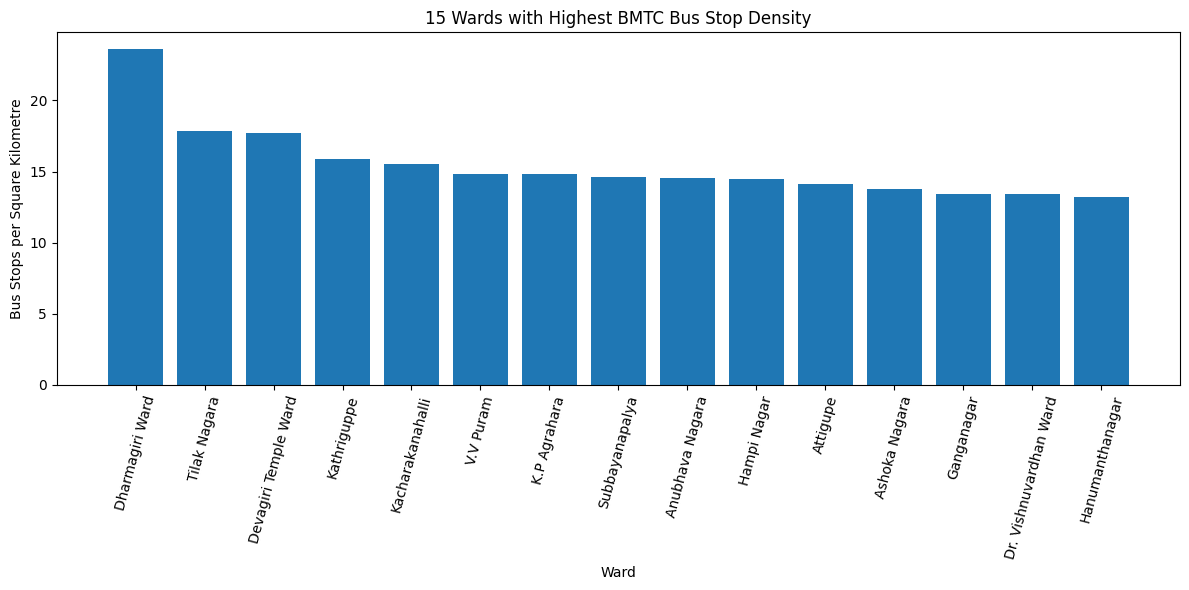

In [ ]:
#create a ward coverage visualisation

top_density = ward_analysis_table.sort_values(
    "stops_per_sq_km",
    ascending=False
).head(15)

plt.figure(figsize=(12, 6))

plt.bar(
    top_density[WARD_NAME].astype(str),
    top_density["stops_per_sq_km"]
)

plt.title("15 Wards with Highest BMTC Bus Stop Density")
plt.xlabel("Ward")
plt.ylabel("Bus Stops per Square Kilometre")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

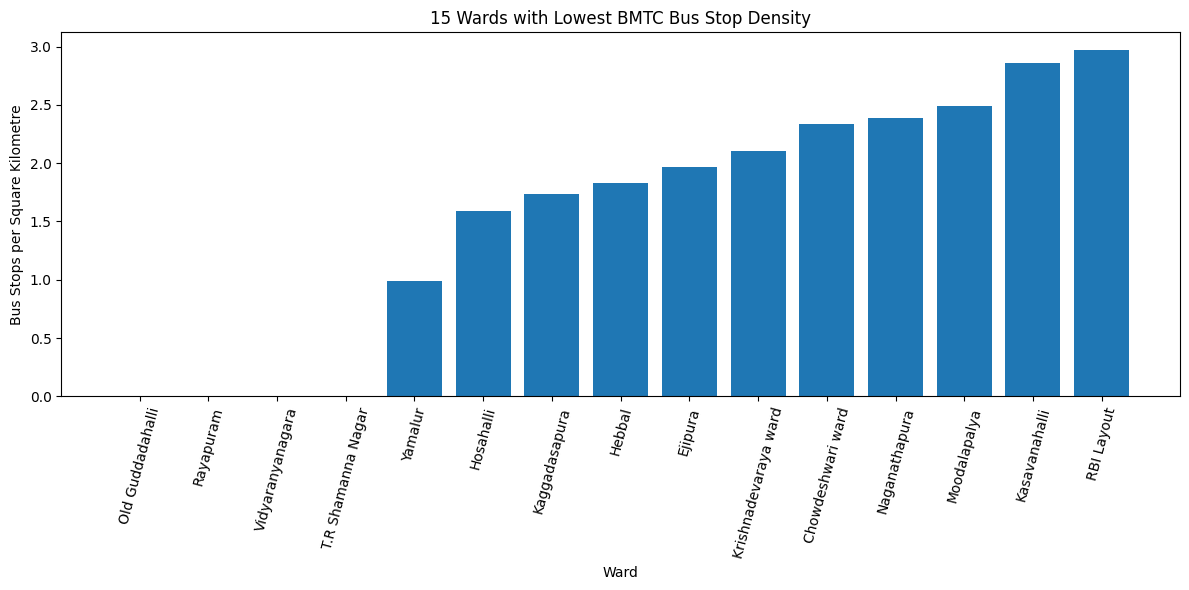

In [ ]:
# Create another chart for the 15 wards with the lowest density:

lowest_density = ward_analysis_table.sort_values(
    "stops_per_sq_km",
    ascending=True
).head(15)

plt.figure(figsize=(12, 6))

plt.bar(
    lowest_density[WARD_NAME].astype(str),
    lowest_density["stops_per_sq_km"]
)

plt.title("15 Wards with Lowest BMTC Bus Stop Density")
plt.xlabel("Ward")
plt.ylabel("Bus Stops per Square Kilometre")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

In [ ]:
#save the ward level analysis

ward_analysis_table.to_csv(
    os.path.join(
        ANALYSIS_PATH,
        "ward_level_bus_coverage.csv"
    ),
    index=False
)

print("Ward coverage CSV saved.")

Ward coverage CSV saved.


In [ ]:
import os

# Make a copy of the geodataframe to avoid mutating the original
wards_export = wards_analysis.copy()

# Convert the secondary geometry column (ward_centroid) to string (WKT) so it can be saved in GeoJSON
if "ward_centroid" in wards_export.columns:
    wards_export["ward_centroid"] = wards_export["ward_centroid"].astype(str)

# Save to GeoJSON with a single active geometry
wards_export.to_file(
    os.path.join(
        ANALYSIS_PATH,
        "ward_bus_coverage.geojson"
    ),
    driver="GeoJSON"
)

print("Ward coverage GeoJSON saved successfully!")

Ward coverage GeoJSON saved successfully!


In [ ]:
#save route level analysis

stops_per_route.to_csv(
    os.path.join(
        ANALYSIS_PATH,
        "route_stop_summary.csv"
    ),
    index=False
)

print("Route-stop summary saved.")

Route-stop summary saved.


In [ ]:
#save the lowest-density and highest-density wards lists

lowest_density.to_csv(
    os.path.join(
        ANALYSIS_PATH,
        "lowest_stop_density_wards.csv"
    ),
    index=False
)

top_density.to_csv(
    os.path.join(
        ANALYSIS_PATH,
        "highest_stop_density_wards.csv"
    ),
    index=False
)

print("Ward ranking files saved.")

Ward ranking files saved.


In [ ]:
print("ANALYSIS FILES")

for file in sorted(os.listdir(ANALYSIS_PATH)):
    print(file)

print("\nREPORT FILES")

for file in sorted(os.listdir(REPORT_PATH)):
    print(file)

ANALYSIS FILES
highest_stop_density_wards.csv
lowest_stop_density_wards.csv
network_kpi_summary.csv
route_stop_summary.csv
ward_bus_coverage.geojson
ward_level_bus_coverage.csv

REPORT FILES
phase3_completion_log.csv
unmatched_bus_stops.csv


In [ ]:
print(
    ward_analysis_table.isna().sum()
)

ward_id                     0
ward_name                   0
ward_area_sq_km             0
total_bus_stops             0
stops_per_sq_km             0
routes_serving_ward         0
nearest_stop_distance_km    0
stop_density_rank           0
route_coverage_rank         0
dtype: int64


In [ ]:
print(
    "Duplicate ward IDs:",
    ward_analysis_table[WARD_ID].duplicated().sum()
)

Duplicate ward IDs: 0


In [ ]:
print(
    "Negative stop counts:",
    (ward_analysis_table["total_bus_stops"] < 0).sum()
)

print(
    "Negative stop density:",
    (ward_analysis_table["stops_per_sq_km"] < 0).sum()
)

print(
    "Negative nearest-stop distance:",
    (ward_analysis_table["nearest_stop_distance_km"] < 0).sum()
)

Negative stop counts: 0
Negative stop density: 0
Negative nearest-stop distance: 0


In [ ]:
#save the final analysis completion log

phase3_log = pd.DataFrame({
    "Task": [
        "Network KPI calculation",
        "Route-stop analysis",
        "Stop coordinate preparation",
        "Ward spatial preparation",
        "Bus stop to ward spatial join",
        "Ward stop density calculation",
        "Ward route coverage calculation",
        "Nearest-stop distance calculation",
        "Ward comparison and ranking",
        "Analysis exports",
        "Quality validation"
    ],
    "Status": ["Completed"] * 11
})

phase3_log.to_csv(
    os.path.join(
        REPORT_PATH,
        "phase3_completion_log.csv"
    ),
    index=False
)

print("Phase 3 completion log saved.")

Phase 3 completion log saved.


PHASE 4

Gap Assessment and Identification of Underserved Wards

In [ ]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from IPython.display import display

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
PROJECT_PATH = "/content/drive/MyDrive/BMTC_Bus_Network_Analytics"

ANALYSIS_PATH = os.path.join(
    PROJECT_PATH, "data", "processed", "analysis"
)

GAP_PATH = os.path.join(
    PROJECT_PATH, "data", "processed", "gap_assessment"
)

REPORT_PATH = os.path.join(
    PROJECT_PATH, "outputs", "gap_assessment_reports"
)

os.makedirs(GAP_PATH, exist_ok=True)
os.makedirs(REPORT_PATH, exist_ok=True)

print("Analysis folder:", ANALYSIS_PATH)
print("Gap assessment folder:", GAP_PATH)
print("Reports folder:", REPORT_PATH)

Analysis folder: /content/drive/MyDrive/BMTC_Bus_Network_Analytics/data/processed/analysis
Gap assessment folder: /content/drive/MyDrive/BMTC_Bus_Network_Analytics/data/processed/gap_assessment
Reports folder: /content/drive/MyDrive/BMTC_Bus_Network_Analytics/outputs/gap_assessment_reports


In [ ]:
required_files = [
    "ward_level_bus_coverage.csv",
    "ward_bus_coverage.geojson",
    "network_kpi_summary.csv",
    "route_stop_summary.csv"
]

for file in required_files:
    path = os.path.join(ANALYSIS_PATH, file)
    print(file, "—", "FOUND" if os.path.exists(path) else "MISSING")

ward_level_bus_coverage.csv — FOUND
ward_bus_coverage.geojson — FOUND
network_kpi_summary.csv — FOUND
route_stop_summary.csv — FOUND


In [ ]:
#load the ward-level analysis

ward_data = pd.read_csv(
    os.path.join(ANALYSIS_PATH, "ward_level_bus_coverage.csv")
)

wards_map = gpd.read_file(
    os.path.join(ANALYSIS_PATH, "ward_bus_coverage.geojson")
)

print("Ward analysis shape:", ward_data.shape)
print("Ward map shape:", wards_map.shape)

display(ward_data.head())

Ward analysis shape: (112, 9)
Ward map shape: (369, 41)


,ward_id,ward_name,ward_area_sq_km,total_bus_stops,stops_per_sq_km,routes_serving_ward,nearest_stop_distance_km,stop_density_rank,route_coverage_rank
0,25,Vinayaka Layout,2.575201,24,9.319660,124,0.242630,75.0,66.0
1,2,Aerocity,10.259064,38,3.704042,244,0.648788,20.0,97.0
2,3,Chowdeshwari ward,6.430308,15,2.332703,131,0.407368,11.0,70.0
3,15,Ramamurthy Nagara,0.802334,4,4.985454,38,0.255381,34.0,30.0
4,58,Nagashettyhalli,0.955453,9,9.419617,92,0.210005,77.0,54.0


In [ ]:
print("WARD ANALYSIS COLUMNS")
print(ward_data.columns.tolist())

print("\nDATA TYPES")
print(ward_data.dtypes)

print("\nWARD MAP COLUMNS")
print(wards_map.columns.tolist())

WARD ANALYSIS COLUMNS
['ward_id', 'ward_name', 'ward_area_sq_km', 'total_bus_stops', 'stops_per_sq_km', 'routes_serving_ward', 'nearest_stop_distance_km', 'stop_density_rank', 'route_coverage_rank']

DATA TYPES
ward_id                       int64
ward_name                    object
ward_area_sq_km             float64
total_bus_stops               int64
stops_per_sq_km             float64
routes_serving_ward           int64
nearest_stop_distance_km    float64
stop_density_rank           float64
route_coverage_rank         float64
dtype: object

WARD MAP COLUMNS
['index', 'tessellate', 'extrude', 'visibility', 'id2', 'Corporation', 'corporation_kn', 'corporation_id', 'ac', 'ac_kn', 'ac_no', 'Assembly', 'ward_id', 'ward_name', 'ward_name_kn', 'TOT_P', 'TOT_M', 'TOT_F', 'SC_P', 'SC_M', 'SC_F', 'ST_P', 'ST_M', 'ST_F', 'low_range', 'high_range', 'RO_Code', 'RO_Division', 'ARO_Code', 'ARO_ Sub Division', 'zone', 'zone_name', 'ward_area_sq_km', 'index_right_x', 'total_bus_stops', 'stops_per_sq

In [ ]:
required_columns = [
    "ward_area_sq_km",
    "total_bus_stops",
    "stops_per_sq_km",
    "routes_serving_ward",
    "nearest_stop_distance_km"
]

missing_columns = [
    col for col in required_columns
    if col not in ward_data.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("All required analysis columns are available.")

All required analysis columns are available.


In [ ]:
possible_id_columns = [
    "ward_id", "ward_no", "ward_number",
    "ward_code", "id"
]

possible_name_columns = [
    "ward_name", "name", "ward"
]

WARD_ID = next(
    (col for col in possible_id_columns if col in ward_data.columns),
    None
)

WARD_NAME = next(
    (col for col in possible_name_columns if col in ward_data.columns),
    None
)

print("Ward ID column:", WARD_ID)
print("Ward name column:", WARD_NAME)

Ward ID column: ward_id
Ward name column: ward_name


In [ ]:
print("Missing values:")
display(ward_data.isna().sum())

print("\nDuplicate ward IDs:")
print(ward_data[WARD_ID].duplicated().sum())

print("\nTotal ward records:", len(ward_data))
print("Unique ward IDs:", ward_data[WARD_ID].nunique())

Missing values:


,0
ward_id,0
ward_name,0
ward_area_sq_km,0
total_bus_stops,0
stops_per_sq_km,0
routes_serving_ward,0
nearest_stop_distance_km,0
stop_density_rank,0
route_coverage_rank,0



Duplicate ward IDs:
0

Total ward records: 112
Unique ward IDs: 112


In [ ]:
#perpare the coverage indicators

#create a separeate assessment dataset

gap_data = ward_data[
    [
        WARD_ID,
        WARD_NAME,
        "ward_area_sq_km",
        "total_bus_stops",
        "stops_per_sq_km",
        "routes_serving_ward",
        "nearest_stop_distance_km"
    ]
].copy()

print("Gap assessment dataset created.")
display(gap_data.head())

Gap assessment dataset created.


,ward_id,ward_name,ward_area_sq_km,total_bus_stops,stops_per_sq_km,routes_serving_ward,nearest_stop_distance_km
0,25,Vinayaka Layout,2.575201,24,9.319660,124,0.242630
1,2,Aerocity,10.259064,38,3.704042,244,0.648788
2,3,Chowdeshwari ward,6.430308,15,2.332703,131,0.407368
3,15,Ramamurthy Nagara,0.802334,4,4.985454,38,0.255381
4,58,Nagashettyhalli,0.955453,9,9.419617,92,0.210005


In [ ]:
#convert KPI columns to numeric

indicator_columns = [
    "ward_area_sq_km",
    "total_bus_stops",
    "stops_per_sq_km",
    "routes_serving_ward",
    "nearest_stop_distance_km"
]

for col in indicator_columns:
    gap_data[col] = pd.to_numeric(
        gap_data[col],
        errors="coerce"
    )

print(gap_data[indicator_columns].dtypes)

ward_area_sq_km             float64
total_bus_stops               int64
stops_per_sq_km             float64
routes_serving_ward           int64
nearest_stop_distance_km    float64
dtype: object


In [ ]:
print("Missing values:")
display(gap_data[indicator_columns].isna().sum())

print("Negative values:")
for col in indicator_columns:
    print(
        col,
        ":",
        (gap_data[col] < 0).sum()
    )

Missing values:


,0
ward_area_sq_km,0
total_bus_stops,0
stops_per_sq_km,0
routes_serving_ward,0
nearest_stop_distance_km,0


Negative values:
ward_area_sq_km : 0
total_bus_stops : 0
stops_per_sq_km : 0
routes_serving_ward : 0
nearest_stop_distance_km : 0


In [ ]:
#create the analysis eligibility check

score_columns = [
    "stops_per_sq_km",
    "routes_serving_ward",
    "nearest_stop_distance_km"
]

gap_data["eligible_for_scoring"] = (
    gap_data[score_columns].notna().all(axis=1)
    &
    (gap_data[score_columns] >= 0).all(axis=1)
)

print("Eligible wards:", gap_data["eligible_for_scoring"].sum())
print("Wards requiring data review:", (~gap_data["eligible_for_scoring"]).sum())

Eligible wards: 112
Wards requiring data review: 0


Calculate Gap Indicators

In [ ]:
density_q25 = gap_data["stops_per_sq_km"].quantile(0.25)

routes_q25 = gap_data["routes_serving_ward"].quantile(0.25)

distance_q75 = gap_data["nearest_stop_distance_km"].quantile(0.75)

print("Stop density — 25th percentile:", density_q25)
print("Route coverage — 25th percentile:", routes_q25)
print("Nearest-stop distance — 75th percentile:", distance_q75)

Stop density — 25th percentile: 4.429180695037077
Route coverage — 25th percentile: 36.5
Nearest-stop distance — 75th percentile: 0.3560826813112207


In [ ]:
#create 3 gap flags

gap_data["low_stop_density_flag"] = (
    gap_data["stops_per_sq_km"] <= density_q25
).astype(int)

gap_data["low_route_coverage_flag"] = (
    gap_data["routes_serving_ward"] <= routes_q25
).astype(int)

gap_data["high_nearest_distance_flag"] = (
    gap_data["nearest_stop_distance_km"] >= distance_q75
).astype(int)

In [ ]:
#count the no. of weaker indicators

gap_flags = [
    "low_stop_density_flag",
    "low_route_coverage_flag",
    "high_nearest_distance_flag"
]

gap_data["number_of_gap_indicators"] = (
    gap_data[gap_flags].sum(axis=1)
)

display(
    gap_data[
        [
            WARD_ID,
            WARD_NAME,
            *gap_flags,
            "number_of_gap_indicators"
        ]
    ].head(15)
)

,ward_id,ward_name,low_stop_density_flag,low_route_coverage_flag,high_nearest_distance_flag,number_of_gap_indicators
0,25,Vinayaka Layout,0,0,0,0
1,2,Aerocity,1,0,1,2
2,3,Chowdeshwari ward,1,0,1,2
3,15,Ramamurthy Nagara,0,0,0,0
4,58,Nagashettyhalli,0,0,0,0
5,21,Kogilu,1,0,1,2
6,46,Yamalur,1,1,1,3
7,24,Agaram,1,0,0,1
8,72,Dasarahalli,0,0,1,1
9,11,Old Baiyappanahalli,0,0,0,0


In [ ]:
#calculate individual concern scores

eligible = gap_data["eligible_for_scoring"]

gap_data["density_concern_score"] = np.nan
gap_data["route_concern_score"] = np.nan
gap_data["distance_concern_score"] = np.nan

gap_data.loc[eligible, "density_concern_score"] = (
    gap_data.loc[eligible, "stops_per_sq_km"]
    .rank(pct=True, ascending=False)
)

gap_data.loc[eligible, "route_concern_score"] = (
    gap_data.loc[eligible, "routes_serving_ward"]
    .rank(pct=True, ascending=False)
)

gap_data.loc[eligible, "distance_concern_score"] = (
    gap_data.loc[eligible, "nearest_stop_distance_km"]
    .rank(pct=True, ascending=True)
)

display(
    gap_data[
        [
            WARD_ID,
            WARD_NAME,
            "density_concern_score",
            "route_concern_score",
            "distance_concern_score"
        ]
    ].head(10)
)

,ward_id,ward_name,density_concern_score,route_concern_score,distance_concern_score
0,25,Vinayaka Layout,0.339286,0.419643,0.526786
1,2,Aerocity,0.830357,0.142857,0.964286
2,3,Chowdeshwari ward,0.910714,0.383929,0.875000
3,15,Ramamurthy Nagara,0.705357,0.736607,0.580357
4,58,Nagashettyhalli,0.321429,0.522321,0.437500
5,21,Kogilu,0.857143,0.464286,0.848214
6,46,Yamalur,0.964286,0.808036,0.982143
7,24,Agaram,0.866071,0.008929,0.133929
8,72,Dasarahalli,0.517857,0.669643,0.892857
9,11,Old Baiyappanahalli,0.625000,0.241071,0.017857


In [ ]:
#calculate the combined gap score

concern_columns = [
    "density_concern_score",
    "route_concern_score",
    "distance_concern_score"
]

gap_data["combined_gap_score"] = np.nan

gap_data.loc[eligible, "combined_gap_score"] = (
    gap_data.loc[eligible, concern_columns].mean(axis=1)
)

display(
    gap_data[
        [
            WARD_ID,
            WARD_NAME,
            *concern_columns,
            "combined_gap_score"
        ]
    ].head(15)
)

,ward_id,ward_name,density_concern_score,route_concern_score,distance_concern_score,combined_gap_score
0,25,Vinayaka Layout,0.339286,0.419643,0.526786,0.428571
1,2,Aerocity,0.830357,0.142857,0.964286,0.645833
2,3,Chowdeshwari ward,0.910714,0.383929,0.875000,0.723214
3,15,Ramamurthy Nagara,0.705357,0.736607,0.580357,0.674107
4,58,Nagashettyhalli,0.321429,0.522321,0.437500,0.427083
5,21,Kogilu,0.857143,0.464286,0.848214,0.723214
6,46,Yamalur,0.964286,0.808036,0.982143,0.918155
7,24,Agaram,0.866071,0.008929,0.133929,0.336310
8,72,Dasarahalli,0.517857,0.669643,0.892857,0.693452
9,11,Old Baiyappanahalli,0.625000,0.241071,0.017857,0.294643


In [ ]:
#create a priority classification

def classify_ward(row):

    if not row["eligible_for_scoring"]:
        return "Insufficient data"

    if (
        row["combined_gap_score"] >= 0.75
        and row["number_of_gap_indicators"] >= 2
    ):
        return "High priority"

    elif (
        row["combined_gap_score"] >= 0.50
        and row["number_of_gap_indicators"] >= 1
    ):
        return "Moderate priority"

    else:
        return "Lower priority"


gap_data["coverage_priority"] = gap_data.apply(
    classify_ward,
    axis=1
)

display(
    gap_data[
        [
            WARD_ID,
            WARD_NAME,
            "combined_gap_score",
            "number_of_gap_indicators",
            "coverage_priority"
        ]
    ].sort_values(
        "combined_gap_score",
        ascending=False
    )
)

,ward_id,ward_name,combined_gap_score,number_of_gap_indicators,coverage_priority
25,51,Old Guddadahalli,0.946429,3,High priority
6,46,Yamalur,0.918155,3,High priority
81,86,Vidyaranyanagara,0.907738,2,High priority
51,17,Kaggadasapura,0.880952,3,High priority
89,90,Krishnadevaraya ward,0.877976,3,High priority
...,...,...,...,...,...
59,55,Ganganagar,0.205357,0,Lower priority
83,82,Attigupe,0.197917,0,Lower priority
22,7,Byrasandra,0.169643,0,Lower priority
23,8,Tilak Nagara,0.169643,0,Lower priority


In [ ]:
#sort wards by combined gap score

ranked_wards = gap_data.sort_values(
    by="combined_gap_score",
    ascending=False,
    na_position="last"
).reset_index(drop=True)

ranked_wards["overall_rank"] = (
    ranked_wards["combined_gap_score"]
    .rank(method="min", ascending=False)
)

display(
    ranked_wards[
        [
            WARD_ID,
            WARD_NAME,
            "overall_rank",
            "stops_per_sq_km",
            "routes_serving_ward",
            "nearest_stop_distance_km",
            "combined_gap_score",
            "coverage_priority"
        ]
    ].head(20)
)

,ward_id,ward_name,overall_rank,stops_per_sq_km,routes_serving_ward,nearest_stop_distance_km,combined_gap_score,coverage_priority
0,51,Old Guddadahalli,1.0,0.000000,0,0.403457,0.946429,High priority
1,46,Yamalur,2.0,0.992144,24,0.697378,0.918155,High priority
2,86,Vidyaranyanagara,3.0,0.000000,0,0.355800,0.907738,High priority
3,17,Kaggadasapura,4.0,1.734083,3,0.356932,0.880952,High priority
4,90,Krishnadevaraya ward,5.0,2.104496,4,0.365745,0.877976,High priority
5,39,Gottigere,6.0,3.885585,33,0.493360,0.836310,High priority
6,26,Ejipura,7.0,1.969176,15,0.320479,0.830357,High priority
7,76,Moodalapalya,8.0,2.489642,1,0.264055,0.825893,High priority
8,99,T.R Shamanna Nagar,9.0,0.000000,0,0.228249,0.818452,High priority
9,33,Naganathapura,10.0,2.385438,22,0.311576,0.809524,High priority


In [ ]:
#extract high-priority candidate wards

high_priority_wards = ranked_wards[
    ranked_wards["coverage_priority"] == "High priority"
].copy()

moderate_priority_wards = ranked_wards[
    ranked_wards["coverage_priority"] == "Moderate priority"
].copy()

print("High-priority wards:", len(high_priority_wards))
print("Moderate-priority wards:", len(moderate_priority_wards))

display(high_priority_wards)

High-priority wards: 15
Moderate-priority wards: 29


,ward_id,ward_name,ward_area_sq_km,total_bus_stops,stops_per_sq_km,routes_serving_ward,nearest_stop_distance_km,eligible_for_scoring,low_stop_density_flag,low_route_coverage_flag,high_nearest_distance_flag,number_of_gap_indicators,density_concern_score,route_concern_score,distance_concern_score,combined_gap_score,coverage_priority,overall_rank
0,51,Old Guddadahalli,0.211625,0,0.000000,0,0.403457,True,1,1,1,3,0.986607,0.986607,0.866071,0.946429,High priority,1.0
1,46,Yamalur,7.055427,7,0.992144,24,0.697378,True,1,1,1,3,0.964286,0.808036,0.982143,0.918155,High priority,2.0
2,86,Vidyaranyanagara,0.305448,0,0.000000,0,0.355800,True,1,1,0,2,0.986607,0.986607,0.750000,0.907738,High priority,3.0
3,17,Kaggadasapura,1.153347,2,1.734083,3,0.356932,True,1,1,1,3,0.946429,0.937500,0.758929,0.880952,High priority,4.0
4,90,Krishnadevaraya ward,0.475173,1,2.104496,4,0.365745,True,1,1,1,3,0.919643,0.928571,0.785714,0.877976,High priority,5.0
5,39,Gottigere,2.058892,8,3.885585,33,0.493360,True,1,1,1,3,0.803571,0.767857,0.937500,0.836310,High priority,6.0
6,26,Ejipura,0.507827,1,1.969176,15,0.320479,True,1,1,0,2,0.928571,0.848214,0.714286,0.830357,High priority,7.0
7,76,Moodalapalya,0.401664,1,2.489642,1,0.264055,True,1,1,0,2,0.892857,0.959821,0.625000,0.825893,High priority,8.0
8,99,T.R Shamanna Nagar,0.350362,0,0.000000,0,0.228249,True,1,1,0,2,0.986607,0.986607,0.482143,0.818452,High priority,9.0
9,33,Naganathapura,3.353682,8,2.385438,22,0.311576,True,1,1,0,2,0.901786,0.830357,0.696429,0.809524,High priority,10.0


In [ ]:
#combine high priority against overall averages

overall_averages = gap_data.loc[
    eligible,
    [
        "stops_per_sq_km",
        "routes_serving_ward",
        "nearest_stop_distance_km"
    ]
].mean()

high_priority_averages = high_priority_wards[
    [
        "stops_per_sq_km",
        "routes_serving_ward",
        "nearest_stop_distance_km"
    ]
].mean()

comparison = pd.DataFrame({
    "Metric": [
        "Bus stops per sq. km",
        "Routes serving ward",
        "Nearest-stop distance (km)"
    ],
    "Overall ward average": overall_averages.values,
    "High-priority ward average": high_priority_averages.values
})

display(comparison)

,Metric,Overall ward average,High-priority ward average
0,Bus stops per sq. km,7.596232,1.872793
1,Routes serving ward,118.535714,23.933333
2,Nearest-stop distance (km),0.257628,0.373147


In [ ]:
#create a summary of priority categories

priority_summary = (
    ranked_wards["coverage_priority"]
    .value_counts()
    .reindex(
        [
            "High priority",
            "Moderate priority",
            "Lower priority",
            "Insufficient data"
        ],
        fill_value=0
    )
    .reset_index()
)

priority_summary.columns = [
    "Coverage Priority",
    "Number of Wards"
]

display(priority_summary)

,Coverage Priority,Number of Wards
0,High priority,15
1,Moderate priority,29
2,Lower priority,68
3,Insufficient data,0


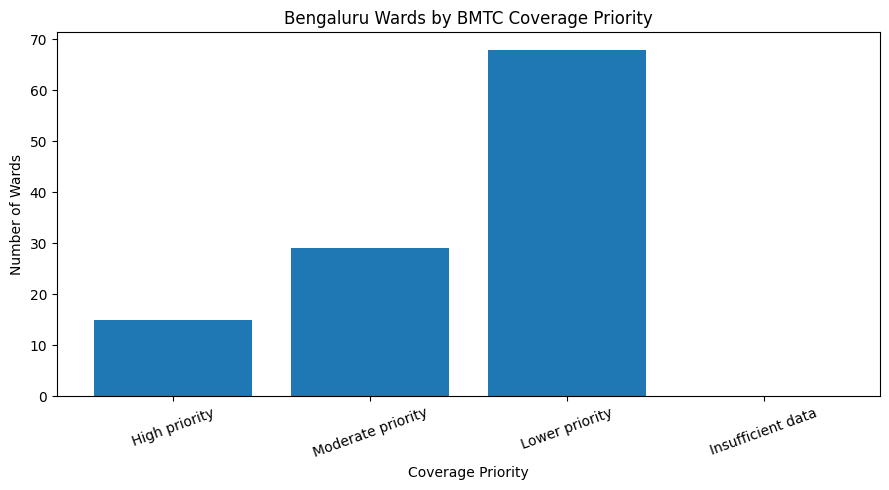

In [ ]:
#visualise the priority distribution

plt.figure(figsize=(9, 5))

plt.bar(
    priority_summary["Coverage Priority"],
    priority_summary["Number of Wards"]
)

plt.title("Bengaluru Wards by BMTC Coverage Priority")
plt.xlabel("Coverage Priority")
plt.ylabel("Number of Wards")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

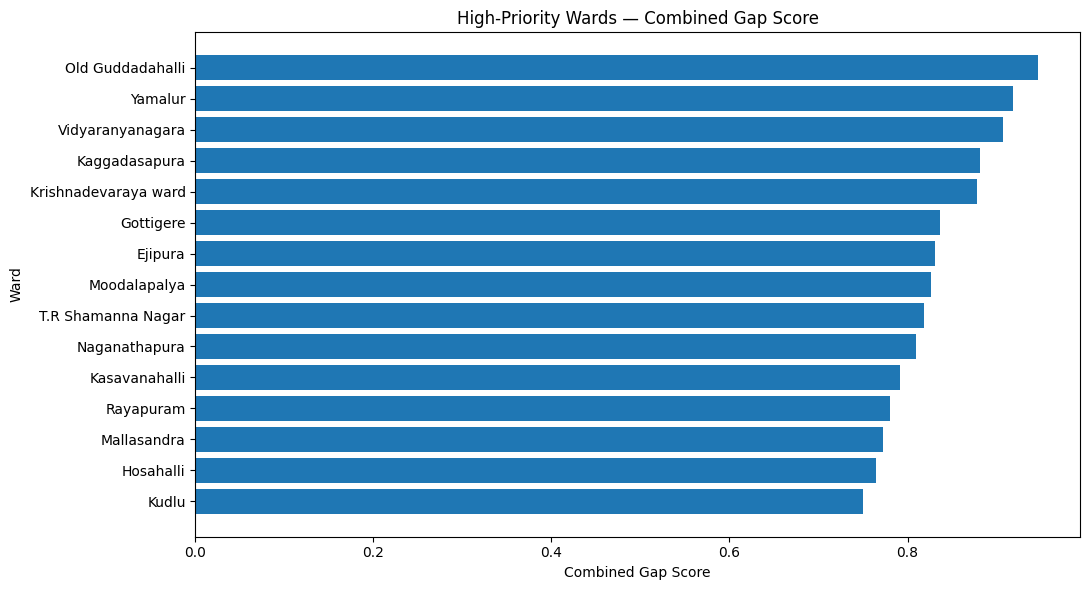

In [ ]:
#visualise high-priority candidate wards

if len(high_priority_wards) > 0:

    plot_data = high_priority_wards.sort_values(
        "combined_gap_score",
        ascending=True
    )

    plt.figure(figsize=(11, 6))

    plt.barh(
        plot_data[WARD_NAME].astype(str),
        plot_data["combined_gap_score"]
    )

    plt.title("High-Priority Wards — Combined Gap Score")
    plt.xlabel("Combined Gap Score")
    plt.ylabel("Ward")
    plt.tight_layout()
    plt.show()

else:
    print("No wards met the high-priority screening criteria.")

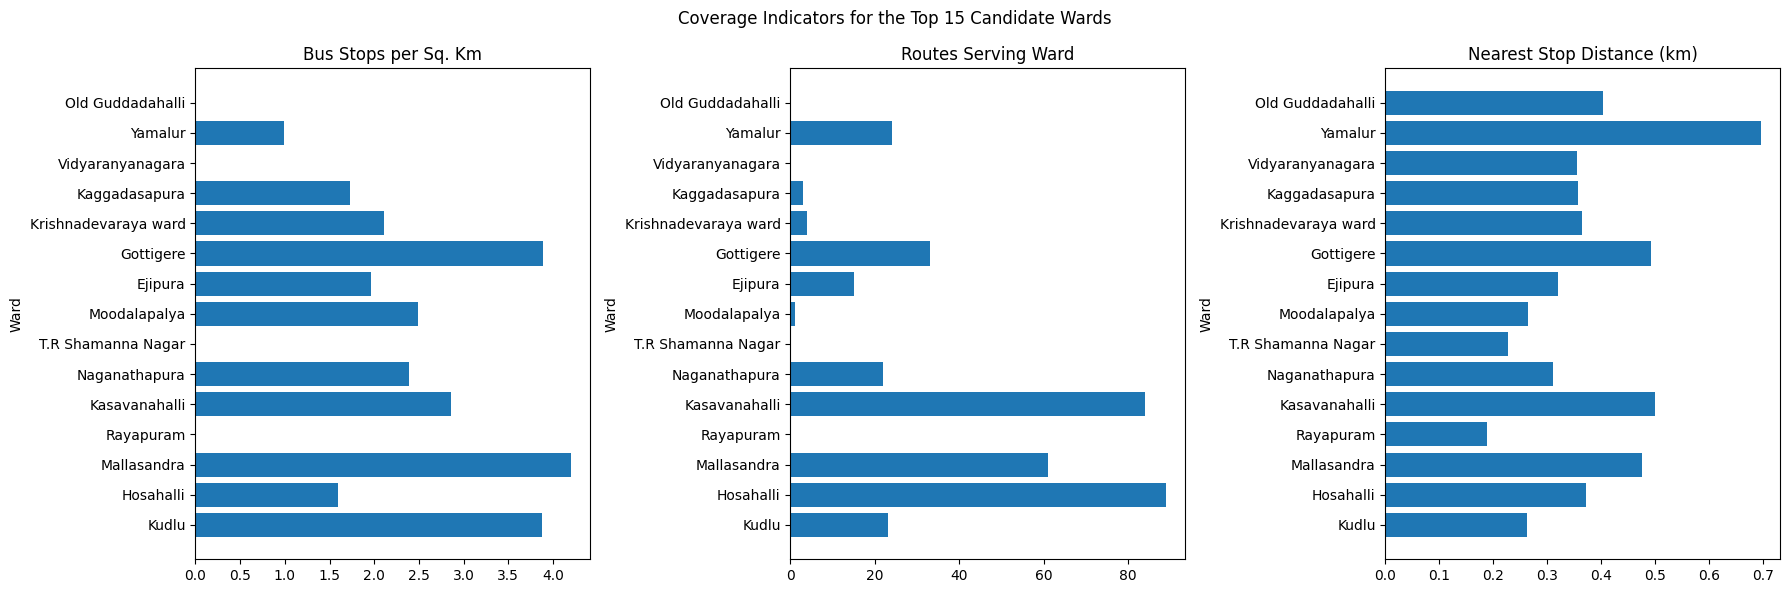

In [ ]:
#compare the 3 indicators for the top candidate wards

top_candidates = ranked_wards[
    ranked_wards["eligible_for_scoring"]
].head(15)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

metrics = [
    ("stops_per_sq_km", "Bus Stops per Sq. Km"),
    ("routes_serving_ward", "Routes Serving Ward"),
    ("nearest_stop_distance_km", "Nearest Stop Distance (km)")
]

for ax, (column, title) in zip(axes, metrics):

    ax.barh(
        top_candidates[WARD_NAME].astype(str),
        top_candidates[column]
    )

    ax.set_title(title)
    ax.set_ylabel("Ward")
    ax.invert_yaxis()

plt.suptitle("Coverage Indicators for the Top 15 Candidate Wards")
plt.tight_layout()
plt.show()

In [ ]:
# Check whether the GeoJSON contains the ward identifier

print("Ward map columns:")
print(wards_map.columns.tolist())

if WARD_ID not in wards_map.columns:
    raise ValueError(
        "The ward ID column from the CSV is not present in the GeoJSON. "
        "Inspect the map columns and identify the matching ward ID."
    )

Ward map columns:
['index', 'tessellate', 'extrude', 'visibility', 'id2', 'Corporation', 'corporation_kn', 'corporation_id', 'ac', 'ac_kn', 'ac_no', 'Assembly', 'ward_id', 'ward_name', 'ward_name_kn', 'TOT_P', 'TOT_M', 'TOT_F', 'SC_P', 'SC_M', 'SC_F', 'ST_P', 'ST_M', 'ST_F', 'low_range', 'high_range', 'RO_Code', 'RO_Division', 'ARO_Code', 'ARO_ Sub Division', 'zone', 'zone_name', 'ward_area_sq_km', 'index_right_x', 'total_bus_stops', 'stops_per_sq_km', 'index_right_y', 'routes_serving_ward', 'ward_centroid', 'nearest_stop_distance_km', 'geometry']


In [ ]:
#join the priority scores to the ward polygons

map_scores = gap_data[
    [
        WARD_ID,
        "combined_gap_score",
        "coverage_priority",
        "number_of_gap_indicators"
    ]
].copy()

wards_map["_ward_join_key"] = (
    wards_map[WARD_ID].astype("string").str.strip()
)

map_scores["_ward_join_key"] = (
    map_scores[WARD_ID].astype("string").str.strip()
)

wards_gap_map = wards_map.merge(
    map_scores.drop(columns=WARD_ID),
    on="_ward_join_key",
    how="left"
)

print("Map records:", len(wards_gap_map))
print(
    "Map records with a priority classification:",
    wards_gap_map["coverage_priority"].notna().sum()
)

Map records: 369
Map records with a priority classification: 369


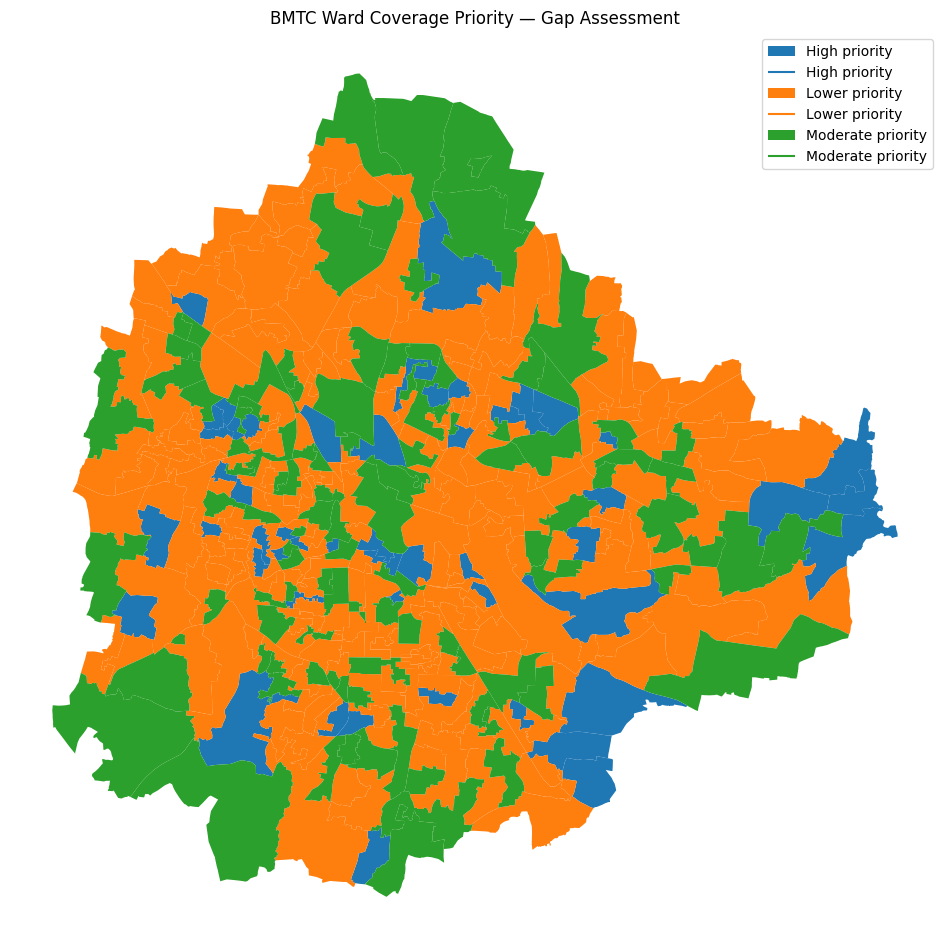

In [ ]:
#plot the coverage priority map

wards_gap_map.plot(
    column="coverage_priority",
    categorical=True,
    legend=True,
    figsize=(12, 12),
    missing_kwds={
        "color": "lightgrey",
        "label": "Insufficient data"
    }
)

plt.title("BMTC Ward Coverage Priority — Gap Assessment")
plt.axis("off")
plt.show()

Test whether the classification is sensitive to the scoring method

In [ ]:
#compare alternative weightings

gap_data["density_weighted_score"] = (
    gap_data["density_concern_score"] * 0.50
    + gap_data["route_concern_score"] * 0.25
    + gap_data["distance_concern_score"] * 0.25
)

gap_data["route_weighted_score"] = (
    gap_data["density_concern_score"] * 0.25
    + gap_data["route_concern_score"] * 0.50
    + gap_data["distance_concern_score"] * 0.25
)

display(
    gap_data[
        [
            WARD_ID,
            WARD_NAME,
            "combined_gap_score",
            "density_weighted_score",
            "route_weighted_score"
        ]
    ].sort_values(
        "combined_gap_score",
        ascending=False
    ).head(15)
)

,ward_id,ward_name,combined_gap_score,density_weighted_score,route_weighted_score
25,51,Old Guddadahalli,0.946429,0.956473,0.956473
6,46,Yamalur,0.918155,0.929688,0.890625
81,86,Vidyaranyanagara,0.907738,0.927455,0.927455
51,17,Kaggadasapura,0.880952,0.897321,0.895089
89,90,Krishnadevaraya ward,0.877976,0.888393,0.890625
18,39,Gottigere,0.836310,0.828125,0.819196
70,26,Ejipura,0.830357,0.854911,0.834821
105,76,Moodalapalya,0.825893,0.842634,0.859375
94,99,T.R Shamanna Nagar,0.818452,0.860491,0.860491
56,33,Naganathapura,0.809524,0.832589,0.814732


In [ ]:
#compare the top 10 wards under the 3 scoring methods

equal_top10 = set(
    gap_data.nlargest(10, "combined_gap_score")[WARD_ID]
)

density_top10 = set(
    gap_data.nlargest(10, "density_weighted_score")[WARD_ID]
)

route_top10 = set(
    gap_data.nlargest(10, "route_weighted_score")[WARD_ID]
)

print("Equal-weight vs density-weight overlap:",
      len(equal_top10 & density_top10), "/ 10")

print("Equal-weight vs route-weight overlap:",
      len(equal_top10 & route_top10), "/ 10")

Equal-weight vs density-weight overlap: 9 / 10
Equal-weight vs route-weight overlap: 9 / 10


In [ ]:
#save the outputs of phase 4

ranked_wards.to_csv(
    os.path.join(
        GAP_PATH,
        "complete_ward_gap_assessment.csv"
    ),
    index=False
)

print("Complete ward assessment saved.")

Complete ward assessment saved.


In [ ]:
high_priority_wards = ranked_wards[
    ranked_wards["coverage_priority"] == "High priority"
].copy()

high_priority_wards.to_csv(
    os.path.join(
        GAP_PATH,
        "high_priority_underserved_ward_candidates.csv"
    ),
    index=False
)

print("High-priority candidate list saved.")

High-priority candidate list saved.


In [ ]:
moderate_priority_wards.to_csv(
    os.path.join(
        GAP_PATH,
        "moderate_priority_ward_candidates.csv"
    ),
    index=False
)

print("Moderate-priority candidate list saved.")

Moderate-priority candidate list saved.


In [ ]:
wards_gap_map = wards_gap_map.drop(
    columns=["_ward_join_key"],
    errors="ignore"
)

wards_gap_map.to_file(
    os.path.join(
        GAP_PATH,
        "bengaluru_ward_coverage_priority.geojson"
    ),
    driver="GeoJSON"
)

print("Ward coverage map saved.")

Ward coverage map saved.


In [ ]:
priority_summary.to_csv(
    os.path.join(
        REPORT_PATH,
        "ward_priority_distribution.csv"
    ),
    index=False
)

comparison.to_csv(
    os.path.join(
        REPORT_PATH,
        "high_priority_vs_overall_comparison.csv"
    ),
    index=False
)

print("Priority reports saved.")

Priority reports saved.


In [ ]:
#save the methodology and thresholds

methodology = pd.DataFrame({
    "Component": [
        "Stop density threshold",
        "Route coverage threshold",
        "Nearest-stop distance threshold",
        "Scoring method",
        "Indicator weights",
        "High priority rule",
        "Moderate priority rule"
    ],
    "Method": [
        "At or below the 25th percentile",
        "At or below the 25th percentile",
        "At or above the 75th percentile",
        "Mean of three percentile-based concern scores",
        "Equal weight: 1/3 per indicator",
        "Score >= 0.75 and at least 2 weaker indicators",
        "Score >= 0.50 and at least 1 weaker indicator"
    ],
    "Purpose": [
        "Identify relatively low stop density",
        "Identify relatively low route coverage",
        "Identify relatively high distance to nearest stop",
        "Create a combined comparison score",
        "Avoid selecting one indicator as the sole measure",
        "Flag stronger candidate coverage gaps",
        "Flag moderate candidate coverage gaps"
    ]
})

display(methodology)

methodology.to_csv(
    os.path.join(
        REPORT_PATH,
        "gap_assessment_methodology.csv"
    ),
    index=False
)

,Component,Method,Purpose
0,Stop density threshold,At or below the 25th percentile,Identify relatively low stop density
1,Route coverage threshold,At or below the 25th percentile,Identify relatively low route coverage
2,Nearest-stop distance threshold,At or above the 75th percentile,Identify relatively high distance to nearest stop
3,Scoring method,Mean of three percentile-based concern scores,Create a combined comparison score
4,Indicator weights,Equal weight: 1/3 per indicator,Avoid selecting one indicator as the sole measure
5,High priority rule,Score >= 0.75 and at least 2 weaker indicators,Flag stronger candidate coverage gaps
6,Moderate priority rule,Score >= 0.50 and at least 1 weaker indicator,Flag moderate candidate coverage gaps


In [ ]:
#save phase 4 quality report

quality_report = pd.DataFrame({
    "Check": [
        "Total ward records",
        "Unique ward IDs",
        "Eligible wards",
        "Wards with insufficient data",
        "Duplicate ward IDs",
        "High-priority wards",
        "Moderate-priority wards",
        "Lower-priority wards",
        "Missing combined scores"
    ],
    "Result": [
        len(gap_data),
        gap_data[WARD_ID].nunique(),
        int(gap_data["eligible_for_scoring"].sum()),
        int((~gap_data["eligible_for_scoring"]).sum()),
        int(gap_data[WARD_ID].duplicated().sum()),
        int((gap_data["coverage_priority"] == "High priority").sum()),
        int((gap_data["coverage_priority"] == "Moderate priority").sum()),
        int((gap_data["coverage_priority"] == "Lower priority").sum()),
        int(gap_data["combined_gap_score"].isna().sum())
    ]
})

display(quality_report)

quality_report.to_csv(
    os.path.join(
        REPORT_PATH,
        "phase4_quality_report.csv"
    ),
    index=False
)

,Check,Result
0,Total ward records,112
1,Unique ward IDs,112
2,Eligible wards,112
3,Wards with insufficient data,0
4,Duplicate ward IDs,0
5,High-priority wards,15
6,Moderate-priority wards,29
7,Lower-priority wards,68
8,Missing combined scores,0


In [ ]:
#verify all saved files

print("PHASE 4 DATA FILES")

for file in sorted(os.listdir(GAP_PATH)):
    print(file)

print("\nPHASE 4 REPORT FILES")

for file in sorted(os.listdir(REPORT_PATH)):
    print(file)

PHASE 4 DATA FILES
bengaluru_ward_coverage_priority.geojson
complete_ward_gap_assessment.csv
high_priority_underserved_ward_candidates.csv
moderate_priority_ward_candidates.csv

PHASE 4 REPORT FILES
gap_assessment_methodology.csv
high_priority_vs_overall_comparison.csv
phase4_completion_log.csv
phase4_quality_report.csv
ward_priority_distribution.csv


In [ ]:
findings = ranked_wards[
    ranked_wards["eligible_for_scoring"]
].head(10)[
    [
        WARD_ID,
        WARD_NAME,
        "stops_per_sq_km",
        "routes_serving_ward",
        "nearest_stop_distance_km",
        "number_of_gap_indicators",
        "combined_gap_score",
        "coverage_priority"
    ]
]

display(findings)

,ward_id,ward_name,stops_per_sq_km,routes_serving_ward,nearest_stop_distance_km,number_of_gap_indicators,combined_gap_score,coverage_priority
0,51,Old Guddadahalli,0.000000,0,0.403457,3,0.946429,High priority
1,46,Yamalur,0.992144,24,0.697378,3,0.918155,High priority
2,86,Vidyaranyanagara,0.000000,0,0.355800,2,0.907738,High priority
3,17,Kaggadasapura,1.734083,3,0.356932,3,0.880952,High priority
4,90,Krishnadevaraya ward,2.104496,4,0.365745,3,0.877976,High priority
5,39,Gottigere,3.885585,33,0.493360,3,0.836310,High priority
6,26,Ejipura,1.969176,15,0.320479,2,0.830357,High priority
7,76,Moodalapalya,2.489642,1,0.264055,2,0.825893,High priority
8,99,T.R Shamanna Nagar,0.000000,0,0.228249,2,0.818452,High priority
9,33,Naganathapura,2.385438,22,0.311576,2,0.809524,High priority


In [ ]:
phase4_log = pd.DataFrame({
    "Task": [
        "Loaded Phase 3 ward analysis",
        "Validated ward-level indicators",
        "Calculated percentile thresholds",
        "Created individual gap flags",
        "Calculated combined gap score",
        "Classified ward coverage priorities",
        "Ranked candidate wards",
        "Compared alternative scoring weights",
        "Created visualisations",
        "Created ward priority map",
        "Exported assessment datasets",
        "Saved methodology and quality reports"
    ],
    "Status": ["Completed"] * 12
})

phase4_log.to_csv(
    os.path.join(
        REPORT_PATH,
        "phase4_completion_log.csv"
    ),
    index=False
)

print("Phase 4 completion log saved.")

Phase 4 completion log saved.


In [ ]:
print("Total wards:", len(ranked_wards))

print("\nPriority classification:")
print(ranked_wards["coverage_priority"].value_counts())

print("\nMissing combined scores:",
      ranked_wards["combined_gap_score"].isna().sum())

print("\nDuplicate ward IDs:",
      ranked_wards[WARD_ID].duplicated().sum())

print("\nPhase 4 completed.")

Total wards: 112

Priority classification:
coverage_priority
Lower priority       68
Moderate priority    29
High priority        15
Name: count, dtype: int64

Missing combined scores: 0

Duplicate ward IDs: 0

Phase 4 completed.


PHASE 5

Feeder Route Planning and Proposal Development

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt

from shapely.geometry import Point, LineString
from IPython.display import display

In [ ]:
PROJECT_PATH = "/content/drive/MyDrive/BMTC_Bus_Network_Analytics"

ANALYSIS_PATH = os.path.join(
    PROJECT_PATH, "data", "processed", "analysis"
)

GAP_PATH = os.path.join(
    PROJECT_PATH, "data", "processed", "gap_assessment"
)

FEEDER_PATH = os.path.join(
    PROJECT_PATH, "data", "processed", "feeder_route_planning"
)

REPORT_PATH = os.path.join(
    PROJECT_PATH, "outputs", "feeder_route_reports"
)

os.makedirs(FEEDER_PATH, exist_ok=True)
os.makedirs(REPORT_PATH, exist_ok=True)

print("Project folders ready.")

Project folders ready.


In [ ]:
gap = pd.read_csv(
    os.path.join(GAP_PATH, "complete_ward_gap_assessment.csv")
)

high_priority = pd.read_csv(
    os.path.join(GAP_PATH, "high_priority_underserved_ward_candidates.csv")
)

moderate_priority = pd.read_csv(
    os.path.join(GAP_PATH, "moderate_priority_ward_candidates.csv")
)

ward_coverage = pd.read_csv(
    os.path.join(ANALYSIS_PATH, "ward_level_bus_coverage.csv")
)

print("Phase 4 data loaded successfully.")

print("Complete assessment:", gap.shape)
print("High-priority wards:", high_priority.shape)
print("Moderate-priority wards:", moderate_priority.shape)
print("Ward coverage:", ward_coverage.shape)

Phase 4 data loaded successfully.
Complete assessment: (112, 18)
High-priority wards: (15, 18)
Moderate-priority wards: (29, 18)
Ward coverage: (112, 9)


In [ ]:
#load cleaned datasets

CLEAN_PATH = os.path.join(
    PROJECT_PATH, "data", "processed", "cleaned_data"
)

print("Available cleaned files:")

for file in os.listdir(CLEAN_PATH):
    print(file)

Available cleaned files:
stops.csv
fare_attributes.csv
trips.csv
feed_info.csv
shapes.csv
agency.csv
stop_times.csv
calendar.csv
translations.csv
routes.csv
fare_rules.csv
wards_cleaned.geojson


In [ ]:
#load cleaned stop-time table

stop_times_path = os.path.join(CLEAN_PATH, "stop_times.csv")

if os.path.exists(stop_times_path):
    stop_times = pd.read_csv(stop_times_path)
    print("Stop times loaded:", stop_times.shape)
else:
    stop_times = None
    print("Stop-times file not found.")

Stop times loaded: (1486887, 6)


In [ ]:
import os
import pandas as pd

# Load the required datasets into memory first
stops = pd.read_csv(os.path.join(CLEAN_PATH, "stops.csv"))
routes = pd.read_csv(os.path.join(CLEAN_PATH, "routes.csv"))
trips = pd.read_csv(os.path.join(CLEAN_PATH, "trips.csv"))

print("GAP ASSESSMENT COLUMNS")
print(gap.columns.tolist())

print("\nHIGH-PRIORITY COLUMNS")
print(high_priority.columns.tolist())

print("\nSTOP COLUMNS")
print(stops.columns.tolist())

print("\nROUTE COLUMNS")
print(routes.columns.tolist())

print("\nTRIP COLUMNS")
print(trips.columns.tolist())

if stop_times is not None:
    print("\nSTOP-TIMES COLUMNS")
    print(stop_times.columns.tolist())

GAP ASSESSMENT COLUMNS
['ward_id', 'ward_name', 'ward_area_sq_km', 'total_bus_stops', 'stops_per_sq_km', 'routes_serving_ward', 'nearest_stop_distance_km', 'eligible_for_scoring', 'low_stop_density_flag', 'low_route_coverage_flag', 'high_nearest_distance_flag', 'number_of_gap_indicators', 'density_concern_score', 'route_concern_score', 'distance_concern_score', 'combined_gap_score', 'coverage_priority', 'overall_rank']

HIGH-PRIORITY COLUMNS
['ward_id', 'ward_name', 'ward_area_sq_km', 'total_bus_stops', 'stops_per_sq_km', 'routes_serving_ward', 'nearest_stop_distance_km', 'eligible_for_scoring', 'low_stop_density_flag', 'low_route_coverage_flag', 'high_nearest_distance_flag', 'number_of_gap_indicators', 'density_concern_score', 'route_concern_score', 'distance_concern_score', 'combined_gap_score', 'coverage_priority', 'overall_rank']

STOP COLUMNS
['stop_name', 'zone_id', 'stop_id', 'stop_desc', 'stop_lat', 'stop_lon']

ROUTE COLUMNS
['route_long_name', 'route_short_name', 'agency_id',

In [ ]:
#inspect all relevant column names

print("GAP ASSESSMENT COLUMNS")
print(gap.columns.tolist())

print("\nHIGH-PRIORITY COLUMNS")
print(high_priority.columns.tolist())

print("\nSTOP COLUMNS")
print(stops.columns.tolist())

print("\nROUTE COLUMNS")
print(routes.columns.tolist())

print("\nTRIP COLUMNS")
print(trips.columns.tolist())

if stop_times is not None:
    print("\nSTOP-TIMES COLUMNS")
    print(stop_times.columns.tolist())

GAP ASSESSMENT COLUMNS
['ward_id', 'ward_name', 'ward_area_sq_km', 'total_bus_stops', 'stops_per_sq_km', 'routes_serving_ward', 'nearest_stop_distance_km', 'eligible_for_scoring', 'low_stop_density_flag', 'low_route_coverage_flag', 'high_nearest_distance_flag', 'number_of_gap_indicators', 'density_concern_score', 'route_concern_score', 'distance_concern_score', 'combined_gap_score', 'coverage_priority', 'overall_rank']

HIGH-PRIORITY COLUMNS
['ward_id', 'ward_name', 'ward_area_sq_km', 'total_bus_stops', 'stops_per_sq_km', 'routes_serving_ward', 'nearest_stop_distance_km', 'eligible_for_scoring', 'low_stop_density_flag', 'low_route_coverage_flag', 'high_nearest_distance_flag', 'number_of_gap_indicators', 'density_concern_score', 'route_concern_score', 'distance_concern_score', 'combined_gap_score', 'coverage_priority', 'overall_rank']

STOP COLUMNS
['stop_name', 'zone_id', 'stop_id', 'stop_desc', 'stop_lat', 'stop_lon']

ROUTE COLUMNS
['route_long_name', 'route_short_name', 'agency_id',

In [ ]:
#Inspect moderate-priority candidates

display(
    moderate_priority.head(10)
)

,ward_id,ward_name,ward_area_sq_km,total_bus_stops,stops_per_sq_km,routes_serving_ward,nearest_stop_distance_km,eligible_for_scoring,low_stop_density_flag,low_route_coverage_flag,high_nearest_distance_flag,number_of_gap_indicators,density_concern_score,route_concern_score,distance_concern_score,combined_gap_score,coverage_priority,overall_rank
0,35,Kammanahalli,0.513158,2,3.897432,14,0.245096,True,1,1,0,2,0.794643,0.857143,0.535714,0.729167,Moderate priority,16.0
1,43,Bheereshwara Nagar,0.833014,6,7.202763,7,0.373939,True,0,1,1,2,0.473214,0.901786,0.812500,0.729167,Moderate priority,16.0
2,16,Kotthur,1.235427,8,6.475492,57,0.503113,True,0,0,1,1,0.562500,0.656250,0.955357,0.724702,Moderate priority,18.0
3,21,Kogilu,11.448281,36,3.144577,106,0.393223,True,1,0,1,2,0.857143,0.464286,0.848214,0.723214,Moderate priority,19.0
4,3,Chowdeshwari ward,6.430308,15,2.332703,131,0.407368,True,1,0,1,2,0.910714,0.383929,0.875000,0.723214,Moderate priority,19.0
5,63,J.P PARK,0.833237,4,4.800556,8,0.230206,True,0,1,0,1,0.723214,0.892857,0.500000,0.705357,Moderate priority,21.0
6,111,Ittamadu,0.458652,3,6.540901,13,0.311261,True,0,1,0,1,0.544643,0.870536,0.687500,0.700893,Moderate priority,22.0
7,12,Kasturi Nagar,3.507950,16,4.561069,135,0.729241,True,0,0,1,1,0.741071,0.361607,0.991071,0.697917,Moderate priority,23.0
8,72,Dasarahalli,0.742079,5,6.737827,53,0.420623,True,0,0,1,1,0.517857,0.669643,0.892857,0.693452,Moderate priority,24.0
9,100,Srinagar,0.292585,1,3.417812,1,0.155117,True,1,1,0,2,0.848214,0.959821,0.267857,0.691964,Moderate priority,25.0


In [ ]:
# Inspect the actual bus stop records

display(stops.head(10))

,stop_name,zone_id,stop_id,stop_desc,stop_lat,stop_lon
0,12th Block Nagarabhavi,21629,21629,12th Block Nagarabhavi (Towards AIT College),12.96018,77.51398
1,12th Block Nagarabhavi,21630,21630,12th Block Nagarabhavi (Towards Nagarabhavi Ci...,12.96076,77.51351
2,14th Main HSR Layout,20568,20568,14th Main HSR Layout (Towards Hebbala),12.91637,77.63472
3,18th Main Jayanagara,22890,22890,18th Main Jayanagara (Towards Jayanagara 4th B...,12.92328,77.58898
4,19th Main 13th Cross HSR Layout,22891,22891,19th Main 13th Cross HSR Layout (Towards Paran...,12.91593,77.65176
5,19th Main 13th Cross HSR Layout,24300,24300,19th Main 13th Cross HSR Layout (Towards Agara...,12.91582,77.65175
6,1st Main Kodichikkanahalli,29393,29393,1st Main Kodichikkanahalli (Towards Kodichikka...,12.89854,77.61543
7,1st Main Kodichikkanahalli,35599,35599,1st Main Kodichikkanahalli (Towards Vijaya Ban...,12.89847,77.61550
8,1st Stage 3rd Block Nagarabhavi (Nayandahalli),22896,22896,1st Stage 3rd Block Nagarabhavi (Nayandahalli)...,12.95302,77.52026
9,1st Stage 3rd Block Nagarabhavi (Summanahalli),22897,22897,1st Stage 3rd Block Nagarabhavi (Summanahalli)...,12.95286,77.52017


In [ ]:
# Inspect the actual route records

display(routes.head(10))

,route_long_name,route_short_name,agency_id,route_type,route_id
0,2nd Stage 9th Block Nagarabhavi ⇔ Shivajinagar...,244-C VSD,1,3,3447
1,5th Block HBR Layout ⇔ Kalyananagara Bus Stand,KLN-HBR,1,3,7041
2,5th Block HBR Layout ⇔ Kempegowda Bus Station,296,1,3,2712
3,5th Block HBR Layout ⇔ Kempegowda Bus Station,296-B,1,3,4821
4,5th Block HBR Layout ⇔ Shivajinagara Bus Station,296-D,1,3,2809
5,8th Mile Dasarahalli ⇔ 8th Mile Dasarahalli,BC-7C,1,3,4673
6,8th Mile Dasarahalli ⇔ 8th Mile Dasarahalli,BC-7CA,1,3,4681
7,8th Mile Dasarahalli ⇔ 8th Mile Dasarahalli Ar...,250-DD,1,3,8574
8,8th Mile Dasarahalli ⇔ Depot-31 Gate,8THM-D31G,1,3,7674
9,8th Mile Dasarahalli ⇔ Depot-31 Gate,BC-7H D31G-8MYL,1,3,5985


In [ ]:
# Check whether the stops have valid coordinates

print("Missing stop coordinates:")

print(
    stops.isna().sum()
)

Missing stop coordinates:
stop_name      0
zone_id        0
stop_id        0
stop_desc    326
stop_lat       0
stop_lon       0
dtype: int64


In [ ]:
#check the coordinate ranges

print(stops[["stop_lat", "stop_lon"]].describe())

          stop_lat     stop_lon
count  9596.000000  9596.000000
mean     13.001860    77.561640
std       0.246450     0.204070
min      12.030800    75.117310
25%      12.901512    77.488843
50%      12.983525    77.577090
75%      13.074065    77.662775
max      17.326300    77.957090


SELECING 2 UNDERSERVED TARGET AREAS

In [ ]:
# Identify the ward ID and ward name columns

print("Possible ward ID columns:")
print([
    col for col in high_priority.columns
    if "id" in col.lower() or "ward" in col.lower()
])

print("\nPossible ward name columns:")
print([
    col for col in high_priority.columns
    if "name" in col.lower()
])

Possible ward ID columns:
['ward_id', 'ward_name', 'ward_area_sq_km', 'routes_serving_ward']

Possible ward name columns:
['ward_name']


In [ ]:
#identify the priority and scoring columns

print([
    col for col in high_priority.columns
    if "priority" in col.lower()
    or "score" in col.lower()
    or "density" in col.lower()
    or "distance" in col.lower()
    or "route" in col.lower()
])

['routes_serving_ward', 'nearest_stop_distance_km', 'low_stop_density_flag', 'low_route_coverage_flag', 'high_nearest_distance_flag', 'density_concern_score', 'route_concern_score', 'distance_concern_score', 'combined_gap_score', 'coverage_priority']


In [ ]:
#preparing a shortlist of candidate wards

candidate_wards = high_priority.copy()

print("Number of high-priority candidates:",
      len(candidate_wards))

display(candidate_wards.head(15))

Number of high-priority candidates: 15


,ward_id,ward_name,ward_area_sq_km,total_bus_stops,stops_per_sq_km,routes_serving_ward,nearest_stop_distance_km,eligible_for_scoring,low_stop_density_flag,low_route_coverage_flag,high_nearest_distance_flag,number_of_gap_indicators,density_concern_score,route_concern_score,distance_concern_score,combined_gap_score,coverage_priority,overall_rank
0,51,Old Guddadahalli,0.211625,0,0.000000,0,0.403457,True,1,1,1,3,0.986607,0.986607,0.866071,0.946429,High priority,1.0
1,46,Yamalur,7.055427,7,0.992144,24,0.697378,True,1,1,1,3,0.964286,0.808036,0.982143,0.918155,High priority,2.0
2,86,Vidyaranyanagara,0.305448,0,0.000000,0,0.355800,True,1,1,0,2,0.986607,0.986607,0.750000,0.907738,High priority,3.0
3,17,Kaggadasapura,1.153347,2,1.734083,3,0.356932,True,1,1,1,3,0.946429,0.937500,0.758929,0.880952,High priority,4.0
4,90,Krishnadevaraya ward,0.475173,1,2.104496,4,0.365745,True,1,1,1,3,0.919643,0.928571,0.785714,0.877976,High priority,5.0
5,39,Gottigere,2.058892,8,3.885585,33,0.493360,True,1,1,1,3,0.803571,0.767857,0.937500,0.836310,High priority,6.0
6,26,Ejipura,0.507827,1,1.969176,15,0.320479,True,1,1,0,2,0.928571,0.848214,0.714286,0.830357,High priority,7.0
7,76,Moodalapalya,0.401664,1,2.489642,1,0.264055,True,1,1,0,2,0.892857,0.959821,0.625000,0.825893,High priority,8.0
8,99,T.R Shamanna Nagar,0.350362,0,0.000000,0,0.228249,True,1,1,0,2,0.986607,0.986607,0.482143,0.818452,High priority,9.0
9,33,Naganathapura,3.353682,8,2.385438,22,0.311576,True,1,1,0,2,0.901786,0.830357,0.696429,0.809524,High priority,10.0


In [ ]:
# Compare candidates by their coverage indicators

comparison_columns = [
    "total_bus_stops",
    "stops_per_sq_km",
    "routes_serving_ward",
    "nearest_stop_distance_km",
    "combined_gap_score"
]

available_columns = [
    col for col in comparison_columns
    if col in candidate_wards.columns
]

display(
    candidate_wards[available_columns].head(15)
)

,total_bus_stops,stops_per_sq_km,routes_serving_ward,nearest_stop_distance_km,combined_gap_score
0,0,0.000000,0,0.403457,0.946429
1,7,0.992144,24,0.697378,0.918155
2,0,0.000000,0,0.355800,0.907738
3,2,1.734083,3,0.356932,0.880952
4,1,2.104496,4,0.365745,0.877976
5,8,3.885585,33,0.493360,0.836310
6,1,1.969176,15,0.320479,0.830357
7,1,2.489642,1,0.264055,0.825893
8,0,0.000000,0,0.228249,0.818452
9,8,2.385438,22,0.311576,0.809524


In [ ]:
# Identify two target wards
#not choosing randomly
TARGET_WARDS = [
    51,
    53
]

print("Selected target wards:", TARGET_WARDS)

Selected target wards: [51, 53]


In [ ]:
#filter the selected wards

ward_id = "ward_id"

selected_wards = candidate_wards[
    candidate_wards[ward_id].isin(TARGET_WARDS)
].copy()

display(selected_wards)

,ward_id,ward_name,ward_area_sq_km,total_bus_stops,stops_per_sq_km,routes_serving_ward,nearest_stop_distance_km,eligible_for_scoring,low_stop_density_flag,low_route_coverage_flag,high_nearest_distance_flag,number_of_gap_indicators,density_concern_score,route_concern_score,distance_concern_score,combined_gap_score,coverage_priority,overall_rank
0,51,Old Guddadahalli,0.211625,0,0.0,0,0.403457,True,1,1,1,3,0.986607,0.986607,0.866071,0.946429,High priority,1.0
11,53,Rayapuram,0.209801,0,0.0,0,0.188536,True,1,1,0,2,0.986607,0.986607,0.366071,0.779762,High priority,12.0


In [ ]:
#save the selected target wards

selected_wards.to_csv(
    os.path.join(FEEDER_PATH, "selected_target_wards.csv"),
    index=False
)

print("Selected target wards saved.")

Selected target wards saved.


Identifying Existing Network Connections

In [ ]:
#create a GeoDataFrame from bus stops

stops_geo = gpd.GeoDataFrame(
    stops.copy(),
    geometry=gpd.points_from_xy(
        stops["stop_lon"],
        stops["stop_lat"]
    ),
    crs="EPSG:4326"
)

stops_geo = stops_geo.to_crs("EPSG:32643")

print("Bus stop GeoDataFrame created.")
display(stops_geo.head())

Bus stop GeoDataFrame created.


,stop_name,zone_id,stop_id,stop_desc,stop_lat,stop_lon,geometry
0,12th Block Nagarabhavi,21629,21629,12th Block Nagarabhavi (Towards AIT College),12.96018,77.51398,POINT (772742.065 1434074.78)
1,12th Block Nagarabhavi,21630,21630,12th Block Nagarabhavi (Towards Nagarabhavi Ci...,12.96076,77.51351,POINT (772690.413 1434138.473)
2,14th Main HSR Layout,20568,20568,14th Main HSR Layout (Towards Hebbala),12.91637,77.63472,POINT (785899.304 1429357.547)
3,18th Main Jayanagara,22890,22890,18th Main Jayanagara (Towards Jayanagara 4th B...,12.92328,77.58898,POINT (780925.133 1430071.759)
4,19th Main 13th Cross HSR Layout,22891,22891,19th Main 13th Cross HSR Layout (Towards Paran...,12.91593,77.65176,POINT (787750.049 1429327.936)


In [ ]:
#Load the ward coverage GeoJSON

wards_geo = gpd.read_file(
    os.path.join(ANALYSIS_PATH, "ward_bus_coverage.geojson")
)

print("Ward map loaded:", wards_geo.shape)
print("CRS:", wards_geo.crs)
print("Columns:", wards_geo.columns.tolist())

Ward map loaded: (369, 41)
CRS: EPSG:32643
Columns: ['index', 'tessellate', 'extrude', 'visibility', 'id2', 'Corporation', 'corporation_kn', 'corporation_id', 'ac', 'ac_kn', 'ac_no', 'Assembly', 'ward_id', 'ward_name', 'ward_name_kn', 'TOT_P', 'TOT_M', 'TOT_F', 'SC_P', 'SC_M', 'SC_F', 'ST_P', 'ST_M', 'ST_F', 'low_range', 'high_range', 'RO_Code', 'RO_Division', 'ARO_Code', 'ARO_ Sub Division', 'zone', 'zone_name', 'ward_area_sq_km', 'index_right_x', 'total_bus_stops', 'stops_per_sq_km', 'index_right_y', 'routes_serving_ward', 'ward_centroid', 'nearest_stop_distance_km', 'geometry']


In [ ]:
import numpy as np

# Inspect data types
print("Data type of ward_id in wards_geo:", wards_geo["ward_id"].dtype)
print("Sample ward_id values in wards_geo:", wards_geo["ward_id"].head().tolist())
print("Target ward IDs:", TARGET_WARDS)

# Safely convert to float or int for matching depending on contents
try:
    # Clean and convert to integer
    wards_geo["ward_id"] = pd.to_numeric(wards_geo["ward_id"], errors="coerce").astype("Int64")
except Exception as e:
    print("Conversion warning:", e)

# Re-attempt the match
selected_ward_map = wards_geo[wards_geo["ward_id"].isin(TARGET_WARDS)].copy()
print("Selected ward geometries matched successfully:", len(selected_ward_map))

Data type of ward_id in wards_geo: object
Sample ward_id values in wards_geo: ['25', '2', '3', '15', '58']
Target ward IDs: [51, 53]
Selected ward geometries matched successfully: 8


In [ ]:
#Convert selected wards to the same projected CRS

selected_ward_map = selected_ward_map.to_crs(
    "EPSG:32643"
)

In [ ]:
# Find existing bus stops inside the selected wards

ward_stop_join = gpd.sjoin(
    stops_geo,
    selected_ward_map[["ward_id", "geometry"]],
    how="inner",
    predicate="within"
)

print("Stops inside selected wards:", len(ward_stop_join))

display(ward_stop_join.head())

Stops inside selected wards: 98


,stop_name,zone_id,stop_id,stop_desc,stop_lat,stop_lon,geometry,index_right,ward_id
36,AGS Layout Arehalli,29462,29462,AGS Layout Arehalli (Towards Last Stop),12.91246,77.53706,POINT (775299.886 1428817.725),63,51
37,AGS Layout Arehalli,35532,35532,AGS Layout Arehalli (Towards Kamakya),12.91246,77.53700,POINT (775293.372 1428817.661),63,51
38,AGS Layout Cross,23014,23014,AGS Layout Cross (Towards AGS Layout),12.91347,77.54088,POINT (775713.537 1428933.626),63,51
39,AGS Layout Cross,24342,24342,AGS Layout Cross (Towards Ittamadu),12.91353,77.54088,POINT (775713.471 1428940.267),63,51
417,Arehalli,21659,21659,Arehalli (Towards Kengeri),12.90834,77.53797,POINT (775403.206 1428362.686),63,51


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Build the two feeder-route concepts

In [ ]:
# Identify nearby existing bus stops

nearby_stop_records = []

for _, ward in selected_ward_map.iterrows():

    centroid = ward.geometry.centroid

    nearby = stops_geo.copy()

    nearby["distance_from_ward_centroid_km"] = (
        nearby.geometry.distance(centroid) / 1000
    )

    nearby = nearby[
        nearby["distance_from_ward_centroid_km"] <= 2
    ].copy()

    # Using 'ward_id' instead of the undefined MAP_WARD_ID_COLUMN
    nearby["ward_id"] = ward["ward_id"]

    nearby_stop_records.append(nearby)

if nearby_stop_records:
    nearby_stops = pd.concat(
        nearby_stop_records,
        ignore_index=True
    )

    display(nearby_stops.head(20))
else:
    nearby_stops = pd.DataFrame()
    print("No nearby stops found.")

,stop_name,zone_id,stop_id,stop_desc,stop_lat,stop_lon,geometry,distance_from_ward_centroid_km,ward_id
0,Agrahara Dasarahalli,20599,20599,Agrahara Dasarahalli (Towards Magadi Road Toll...,12.97853,77.54293,POINT (775864.468 1436136.967),1.834937,51
1,Agrahara Dasarahalli,20600,20600,Agrahara Dasarahalli (Towards Kottigepalya),12.97874,77.54121,POINT (775677.534 1436158.349),1.914200,51
2,Aralimara Industrial Area Rajajinagara,21654,21654,Aralimara Industrial Area Rajajinagara (Toward...,12.97858,77.54902,POINT (776525.468 1436149.103),1.785597,51
3,Aralimara Industrial Area Rajajinagara,21655,21655,Aralimara Industrial Area Rajajinagara (Toward...,12.97857,77.54871,POINT (776491.829 1436147.66),1.781405,51
4,Attiguppe,20613,20613,Attiguppe (Towards Vijayanagara),12.95789,77.53385,POINT (774901.547 1433842.637),1.553663,51
5,Attiguppe,21674,21674,Attiguppe (Towards R P C Layout),12.95786,77.53431,POINT (774951.516 1433839.812),1.507761,51
6,Attiguppe,23208,23208,Attiguppe (Towards West of Chord Road),12.95785,77.53437,POINT (774958.04 1433838.77),1.502025,51
7,Attiguppe,35427,35427,Attiguppe (Towards Deepanjali Nagara),12.95809,77.53395,POINT (774912.183 1433864.882),1.536194,51
8,Attiguppe Metro Station,39679,39679,Attiguppe Metro Station (Towards Vijayanagara),12.96245,77.53377,POINT (774887.854 1434347.27),1.474965,51
9,BCC Layout Cross,29805,29805,BCC Layout Cross (Towards BCC Layout),12.95473,77.53486,POINT (775014.66 1433493.964),1.608141,51


In [ ]:
# Save the nearby stop records\

if not nearby_stops.empty:
    nearby_stops.drop(
        columns="geometry",
        errors="ignore"
    ).to_csv(
        os.path.join(FEEDER_PATH, "nearby_existing_bus_stops.csv"),
        index=False
    )

    print("Nearby stops saved.")

Nearby stops saved.


In [ ]:
# Identify route connections for the nearby stops

if stop_times is not None:

    print("Stop-times columns:", stop_times.columns.tolist())
    print("Trip columns:", trips.columns.tolist())
    print("Route columns:", routes.columns.tolist())

Stop-times columns: ['trip_id', 'arrival_time', 'departure_time', 'stop_id', 'stop_sequence', 'stop_headsign']
Trip columns: ['route_id', 'service_id', 'trip_headsign', 'direction_id', 'shape_id', 'trip_id']
Route columns: ['route_long_name', 'route_short_name', 'agency_id', 'route_type', 'route_id']


In [ ]:
if stop_times is not None:

    existing_connections = (
        stop_times[
            ["trip_id", "stop_id"]
        ]
        .merge(
            trips[["trip_id", "route_id"]],
            on="trip_id",
            how="left"
        )
        .merge(
            routes[["route_id"]],
            on="route_id",
            how="left"
        )
    )

    print("Existing stop-route connections:")
    display(existing_connections.head())

Existing stop-route connections:


,trip_id,stop_id,route_id
0,34162,27263,3447
1,34162,20985,3447
2,34162,20921,3447
3,34162,35387,3447
4,34162,21200,3447


In [ ]:
TARGET_WARDS = [51, 53]

WARD_NAMES = {
    51: "Old Guddadahalli",
    53: "Rayapuram"
}

print("Selected feeder target areas:")

for ward_id in TARGET_WARDS:
    print(ward_id, "-", WARD_NAMES[ward_id])

Selected feeder target areas:
51 - Old Guddadahalli
53 - Rayapuram


In [ ]:
# Load the nearby stops and calculate existing route connections

# Load nearby stops if the DataFrame is not already available.

if "nearby_stops" not in globals():
    nearby_stops = pd.read_csv(
        os.path.join(
            FEEDER_PATH,
            "nearby_existing_bus_stops.csv"
        )
    )

# Confirm required GTFS columns.
required_stop_time_cols = {"trip_id", "stop_id"}
required_trip_cols = {"trip_id", "route_id"}

if stop_times is None:
    raise ValueError("The stop_times table is required.")

if not required_stop_time_cols.issubset(stop_times.columns):
    raise ValueError("Required trip_id/stop_id columns are missing.")

if not required_trip_cols.issubset(trips.columns):
    raise ValueError("Required trip_id/route_id columns are missing.")

# Build stop-to-route relationships.
existing_connections = (
    stop_times[["trip_id", "stop_id"]]
    .merge(
        trips[["trip_id", "route_id"]],
        on="trip_id",
        how="inner"
    )
    .dropna(subset=["stop_id", "route_id"])
    .drop_duplicates()
)

# Count distinct existing routes at each stop.
stop_route_counts = (
    existing_connections
    .groupby("stop_id")["route_id"]
    .nunique()
    .reset_index(name="existing_route_count")
)

# Attach connectivity counts to nearby stops.
nearby_stops["stop_id"] = nearby_stops["stop_id"].astype(str)
stop_route_counts["stop_id"] = stop_route_counts["stop_id"].astype(str)

nearby_stops = nearby_stops.merge(
    stop_route_counts,
    on="stop_id",
    how="left"
)

nearby_stops["existing_route_count"] = (
    nearby_stops["existing_route_count"].fillna(0).astype(int)
)

print("Nearby stops with route connectivity calculated.")
display(nearby_stops.head(10))

Nearby stops with route connectivity calculated.


,stop_name,zone_id,stop_id,stop_desc,stop_lat,stop_lon,geometry,distance_from_ward_centroid_km,ward_id,existing_route_count
0,Agrahara Dasarahalli,20599,20599,Agrahara Dasarahalli (Towards Magadi Road Toll...,12.97853,77.54293,POINT (775864.468 1436136.967),1.834937,51,156
1,Agrahara Dasarahalli,20600,20600,Agrahara Dasarahalli (Towards Kottigepalya),12.97874,77.54121,POINT (775677.534 1436158.349),1.914200,51,153
2,Aralimara Industrial Area Rajajinagara,21654,21654,Aralimara Industrial Area Rajajinagara (Toward...,12.97858,77.54902,POINT (776525.468 1436149.103),1.785597,51,18
3,Aralimara Industrial Area Rajajinagara,21655,21655,Aralimara Industrial Area Rajajinagara (Toward...,12.97857,77.54871,POINT (776491.829 1436147.66),1.781405,51,20
4,Attiguppe,20613,20613,Attiguppe (Towards Vijayanagara),12.95789,77.53385,POINT (774901.547 1433842.637),1.553663,51,75
5,Attiguppe,21674,21674,Attiguppe (Towards R P C Layout),12.95786,77.53431,POINT (774951.516 1433839.812),1.507761,51,2
6,Attiguppe,23208,23208,Attiguppe (Towards West of Chord Road),12.95785,77.53437,POINT (774958.04 1433838.77),1.502025,51,3
7,Attiguppe,35427,35427,Attiguppe (Towards Deepanjali Nagara),12.95809,77.53395,POINT (774912.183 1433864.882),1.536194,51,80
8,Attiguppe Metro Station,39679,39679,Attiguppe Metro Station (Towards Vijayanagara),12.96245,77.53377,POINT (774887.854 1434347.27),1.474965,51,81
9,BCC Layout Cross,29805,29805,BCC Layout Cross (Towards BCC Layout),12.95473,77.53486,POINT (775014.66 1433493.964),1.608141,51,4


### Refined & Optimized Network Connectivity Pipeline
This optimized block applies a **filter-first** strategy. By filtering the large `stop_times` table to only include the specific stops present in our shortlisted `nearby_stops` dataframe *before* performing the join with `trips`, we avoid heavy memory consumption and speed up the calculation significantly.

In [ ]:
import os
import pandas as pd

# Standardize stop_id in our target subset to avoid float-to-string conversion mismatches
nearby_stops_df = nearby_stops.copy()
nearby_stops_df['stop_id'] = nearby_stops_df['stop_id'].astype(str).str.split('.').str[0].str.strip()
target_stop_ids = set(nearby_stops_df['stop_id'])

# Ensure GTFS reference tables are available
if 'stop_times' in globals() and stop_times is not None:
    # 1. Filter the large stop_times dataset first to include only relevant stops
    stop_times_filtered = stop_times[
        stop_times['stop_id'].astype(str).str.split('.').str[0].str.strip().isin(target_stop_ids)
    ][['trip_id', 'stop_id']].copy()

    stop_times_filtered['stop_id'] = stop_times_filtered['stop_id'].astype(str).str.split('.').str[0].str.strip()

    # 2. Extract trip-to-route mappings
    trips_subset = trips[['trip_id', 'route_id']].dropna().drop_duplicates()

    # 3. Join on filtered subsets
    connections = stop_times_filtered.merge(trips_subset, on='trip_id', how='inner')

    # 4. Count unique routes per stop
    route_counts = (
        connections.groupby('stop_id')['route_id']
        .nunique()
        .reset_index(name='optimized_route_count')
    )

    # 5. Merge connectivity metrics back to the nearby stops dataframe
    nearby_stops_optimized = nearby_stops_df.merge(
        route_counts,
        on='stop_id',
        how='left'
    )
    nearby_stops_optimized['optimized_route_count'] = (
        nearby_stops_optimized['optimized_route_count'].fillna(0).astype(int)
    )

    print(f"Processing completed! Found route connectivity for {len(route_counts)} stops.")
    display(nearby_stops_optimized.head(10))
else:
    print("GTFS stop_times or trips table is not loaded. Please ensure Phase 2/3 datasets are in memory.")

Processing completed! Found route connectivity for 641 stops.


,stop_name,zone_id,stop_id,stop_desc,stop_lat,stop_lon,geometry,distance_from_ward_centroid_km,ward_id,existing_route_count,optimized_route_count
0,Agrahara Dasarahalli,20599,20599,Agrahara Dasarahalli (Towards Magadi Road Toll...,12.97853,77.54293,POINT (775864.468 1436136.967),1.834937,51,156,156
1,Agrahara Dasarahalli,20600,20600,Agrahara Dasarahalli (Towards Kottigepalya),12.97874,77.54121,POINT (775677.534 1436158.349),1.914200,51,153,153
2,Aralimara Industrial Area Rajajinagara,21654,21654,Aralimara Industrial Area Rajajinagara (Toward...,12.97858,77.54902,POINT (776525.468 1436149.103),1.785597,51,18,18
3,Aralimara Industrial Area Rajajinagara,21655,21655,Aralimara Industrial Area Rajajinagara (Toward...,12.97857,77.54871,POINT (776491.829 1436147.66),1.781405,51,20,20
4,Attiguppe,20613,20613,Attiguppe (Towards Vijayanagara),12.95789,77.53385,POINT (774901.547 1433842.637),1.553663,51,75,75
5,Attiguppe,21674,21674,Attiguppe (Towards R P C Layout),12.95786,77.53431,POINT (774951.516 1433839.812),1.507761,51,2,2
6,Attiguppe,23208,23208,Attiguppe (Towards West of Chord Road),12.95785,77.53437,POINT (774958.04 1433838.77),1.502025,51,3,3
7,Attiguppe,35427,35427,Attiguppe (Towards Deepanjali Nagara),12.95809,77.53395,POINT (774912.183 1433864.882),1.536194,51,80,80
8,Attiguppe Metro Station,39679,39679,Attiguppe Metro Station (Towards Vijayanagara),12.96245,77.53377,POINT (774887.854 1434347.27),1.474965,51,81,81
9,BCC Layout Cross,29805,29805,BCC Layout Cross (Towards BCC Layout),12.95473,77.53486,POINT (775014.66 1433493.964),1.608141,51,4,4


In [ ]:
# Save the connectivity summary

nearby_stops.to_csv(
    os.path.join(
        FEEDER_PATH,
        "nearby_stop_connectivity_summary.csv"
    ),
    index=False
)

print("Connectivity summary saved.")

Connectivity summary saved.


In [ ]:
# Identify the best connection stops in each ward

selected_stop_records = []

for ward_id in TARGET_WARDS:

    ward_stops = nearby_stops[
        nearby_stops["ward_id"] == ward_id
    ].copy()

    # Remove duplicate stop IDs.
    ward_stops = ward_stops.drop_duplicates(
        subset="stop_id"
    )

    # Keep stops with at least one known existing route.
    connected = ward_stops[
        ward_stops["existing_route_count"] > 0
    ].copy()

    if len(connected) < 2:
        raise ValueError(
            f"Ward {ward_id} has fewer than two nearby stops "
            "with existing route connections. Review the GTFS data."
        )

    connected = connected.sort_values(
        "existing_route_count",
        ascending=False
    )

    # Start: stop with highest route connectivity.
    start = connected.iloc[0]

    # End: well-connected stop at least 0.5 km away, if available.
    alternatives = connected[
        connected["stop_id"] != start["stop_id"]
    ].copy()

    alternatives["distance_from_start_km"] = np.sqrt(
        ((alternatives["stop_lat"] - start["stop_lat"]) * 111.0) ** 2
        +
        ((alternatives["stop_lon"] - start["stop_lon"]) * 111.0
         * np.cos(np.radians(start["stop_lat"]))) ** 2
    )

    separated = alternatives[
        alternatives["distance_from_start_km"] >= 0.5
    ]

    if not separated.empty:
        end = separated.sort_values(
            ["existing_route_count", "distance_from_start_km"],
            ascending=[False, False]
        ).iloc[0]
    else:
        end = alternatives.sort_values(
            "distance_from_start_km",
            ascending=False
        ).iloc[0]

    selected_stop_records.extend([
        {
            "proposed_route_id": f"FEEDER_{TARGET_WARDS.index(ward_id)+1:02d}",
            "ward_id": ward_id,
            "stop_role": "Start",
            "stop_id": start["stop_id"],
            "stop_name": start["stop_name"],
            "latitude": start["stop_lat"],
            "longitude": start["stop_lon"],
            "existing_route_count": start["existing_route_count"],
            "distance_from_ward_centroid_km":
                start["distance_from_ward_centroid_km"]
        },
        {
            "proposed_route_id": f"FEEDER_{TARGET_WARDS.index(ward_id)+1:02d}",
            "ward_id": ward_id,
            "stop_role": "End",
            "stop_id": end["stop_id"],
            "stop_name": end["stop_name"],
            "latitude": end["stop_lat"],
            "longitude": end["stop_lon"],
            "existing_route_count": end["existing_route_count"],
            "distance_from_ward_centroid_km":
                end["distance_from_ward_centroid_km"]
        }
    ])

terminal_stops = pd.DataFrame(selected_stop_records)

display(terminal_stops)

,proposed_route_id,ward_id,stop_role,stop_id,stop_name,latitude,longitude,existing_route_count,distance_from_ward_centroid_km
0,FEEDER_01,51,Start,21868,CSI Hospital,12.98983,77.59938,291,1.999365
1,FEEDER_01,51,End,22585,Vasantha Nagara,12.99278,77.59503,255,1.445625
2,FEEDER_02,53,Start,24016,Yeshawanthapura Bus Station,13.01771,77.55657,261,1.454966
3,FEEDER_02,53,End,20971,Link Road,12.99426,77.57388,253,1.750589


In [ ]:
# Select intermediate stops between the two terminals

intermediate_records = []

for route_id in terminal_stops["proposed_route_id"].unique():

    terminals = terminal_stops[
        terminal_stops["proposed_route_id"] == route_id
    ]

    start = terminals[
        terminals["stop_role"] == "Start"
    ].iloc[0]

    end = terminals[
        terminals["stop_role"] == "End"
    ].iloc[0]

    ward_id = int(start["ward_id"])

    candidates = nearby_stops[
        (nearby_stops["ward_id"] == ward_id) &
        (nearby_stops["existing_route_count"] > 0)
    ].drop_duplicates("stop_id").copy()

    candidates = candidates[
        ~candidates["stop_id"].isin(
            [start["stop_id"], end["stop_id"]]
        )
    ]

    # Approximate local projected coordinates in kilometres using "latitude" and "longitude" from terminal_stops
    lat0 = start["latitude"]
    lon0 = start["longitude"]

    def local_xy(lat, lon):
        x = (lon - lon0) * 111.32 * np.cos(np.radians(lat0))
        y = (lat - lat0) * 111.32
        return np.array([x, y])

    start_xy = local_xy(start["latitude"], start["longitude"])
    end_xy = local_xy(end["latitude"], end["longitude"])

    line_vector = end_xy - start_xy
    line_length_squared = np.dot(line_vector, line_vector)

    if line_length_squared == 0:
        continue

    candidate_xy = np.array([
        local_xy(lat, lon)
        for lat, lon in zip(
            candidates["stop_lat"],
            candidates["stop_lon"]
        )
    ])

    projections = np.dot(
        candidate_xy - start_xy,
        line_vector
    ) / line_length_squared

    candidates["line_position"] = projections

    projected_points = (
        start_xy
        + projections[:, None] * line_vector
    )

    candidates["distance_from_corridor_km" ] = np.linalg.norm(
        candidate_xy - projected_points,
        axis=1
    )

    candidates = candidates[
        (candidates["line_position"] > 0) &
        (candidates["line_position"] < 1)
    ].sort_values("distance_from_corridor_km")

    chosen = candidates.head(3).sort_values("line_position")

    for sequence, (_, stop) in enumerate(chosen.iterrows(), start=2):
        intermediate_records.append({
            "proposed_route_id": route_id,
            "ward_id": ward_id,
            "stop_sequence": sequence,
            "stop_id": stop["stop_id"],
            "stop_name": stop["stop_name"],
            "latitude": stop["stop_lat"],
            "longitude": stop["stop_lon"],
            "existing_route_count": stop["existing_route_count"],
            "stop_type": "Existing GTFS stop"
        })

intermediate_stops = pd.DataFrame(intermediate_records)

display(intermediate_stops)

,proposed_route_id,ward_id,stop_sequence,stop_id,stop_name,latitude,longitude,existing_route_count,stop_type
0,FEEDER_01,51,2,38454,Bhagwan Mahaveer Jain Hospital,12.99059,77.59596,1,Existing GTFS stop
1,FEEDER_01,51,3,21805,Cantonment Railway Station,12.99370,77.59689,239,Existing GTFS stop
2,FEEDER_01,51,4,32206,Cantonment Railway Station,12.99475,77.59711,3,Existing GTFS stop
3,FEEDER_02,53,2,29383,Malleshwaram 15th Cross(8th Main),13.00718,77.56424,2,Existing GTFS stop
4,FEEDER_02,53,3,35424,Malleshwaram 15th Cross(8th Main),13.00715,77.56423,4,Existing GTFS stop
5,FEEDER_02,53,4,20988,Malleshwara Circle,12.99782,77.57140,201,Existing GTFS stop


In [ ]:
# Build the complete stop sequence

sequence_records = []

for route_id in terminal_stops["proposed_route_id"].unique():

    terminals = terminal_stops[
        terminal_stops["proposed_route_id"] == route_id
    ]

    start = terminals[
        terminals["stop_role"] == "Start"
    ].iloc[0]

    end = terminals[
        terminals["stop_role"] == "End"
    ].iloc[0]

    sequence_records.append({
        "proposed_route_id": route_id,
        "ward_id": int(start["ward_id"]),
        "stop_sequence": 1,
        "stop_id": start["stop_id"],
        "stop_name": start["stop_name"],
        "latitude": start["latitude"],
        "longitude": start["longitude"],
        "existing_route_count": start["existing_route_count"],
        "stop_type": "Existing GTFS stop"
    })

    if not intermediate_stops.empty:
        route_intermediates = intermediate_stops[
            intermediate_stops["proposed_route_id"] == route_id
        ]

        sequence_records.extend(
            route_intermediates.to_dict("records")
        )

    sequence_records.append({
        "proposed_route_id": route_id,
        "ward_id": int(end["ward_id"]),
        "stop_sequence": 999,
        "stop_id": end["stop_id"],
        "stop_name": end["stop_name"],
        "latitude": end["latitude"],
        "longitude": end["longitude"],
        "existing_route_count": end["existing_route_count"],
        "stop_type": "Existing GTFS stop"
    })

proposed_stops = pd.DataFrame(sequence_records)

# Re-number stops in order.
proposed_stops = proposed_stops.sort_values(
    ["proposed_route_id", "stop_sequence"]
)

proposed_stops["stop_sequence"] = (
    proposed_stops.groupby("proposed_route_id").cumcount() + 1
)

display(proposed_stops)

,proposed_route_id,ward_id,stop_sequence,stop_id,stop_name,latitude,longitude,existing_route_count,stop_type
0,FEEDER_01,51,1,21868,CSI Hospital,12.98983,77.59938,291,Existing GTFS stop
1,FEEDER_01,51,2,38454,Bhagwan Mahaveer Jain Hospital,12.99059,77.59596,1,Existing GTFS stop
2,FEEDER_01,51,3,21805,Cantonment Railway Station,12.99370,77.59689,239,Existing GTFS stop
3,FEEDER_01,51,4,32206,Cantonment Railway Station,12.99475,77.59711,3,Existing GTFS stop
4,FEEDER_01,51,5,22585,Vasantha Nagara,12.99278,77.59503,255,Existing GTFS stop
5,FEEDER_02,53,1,24016,Yeshawanthapura Bus Station,13.01771,77.55657,261,Existing GTFS stop
6,FEEDER_02,53,2,29383,Malleshwaram 15th Cross(8th Main),13.00718,77.56424,2,Existing GTFS stop
7,FEEDER_02,53,3,35424,Malleshwaram 15th Cross(8th Main),13.00715,77.56423,4,Existing GTFS stop
8,FEEDER_02,53,4,20988,Malleshwara Circle,12.99782,77.57140,201,Existing GTFS stop
9,FEEDER_02,53,5,20971,Link Road,12.99426,77.57388,253,Existing GTFS stop


In [ ]:
# Calculate existing BMTC routes connected by each proposal

route_connection_records = []

for route_id in proposed_stops["proposed_route_id"].unique():

    route_stop_ids = proposed_stops[
        proposed_stops["proposed_route_id"] == route_id
    ]["stop_id"].astype(str).unique()

    connections = existing_connections[
        existing_connections["stop_id"].astype(str).isin(route_stop_ids)
    ]

    connected_route_ids = sorted(
        connections["route_id"].dropna().astype(str).unique()
    )

    route_connection_records.append({
        "proposed_route_id": route_id,
        "number_of_existing_routes_connected": len(connected_route_ids),
        "existing_route_ids": ", ".join(connected_route_ids)
    })

route_connections_summary = pd.DataFrame(
    route_connection_records
)

display(route_connections_summary)

,proposed_route_id,number_of_existing_routes_connected,existing_route_ids
0,FEEDER_01,320,"1045, 1052, 1055, 1258, 1272, 1307, 1324, 1325..."
1,FEEDER_02,396,"1086, 1104, 1164, 1313, 1419, 1483, 1484, 1492..."


In [ ]:
# Create the two completed feeder proposals

proposal_records = []

for route_id in proposed_stops["proposed_route_id"].unique():

    route_data = proposed_stops[
        proposed_stops["proposed_route_id"] == route_id
    ].sort_values("stop_sequence")

    start = route_data.iloc[0]
    end = route_data.iloc[-1]

    # Fixed NameError: changed 'route_connection_summary' to 'route_connections_summary'
    connections = route_connections_summary[
        route_connections_summary["proposed_route_id"] == route_id
    ].iloc[0]

    proposal_records.append({
        "proposed_route_id": route_id,
        "target_ward_id": int(start["ward_id"]),
        "target_ward_name": WARD_NAMES[int(start["ward_id"])],
        "proposed_start_stop_id": start["stop_id"],
        "proposed_start_stop_name": start["stop_name"],
        "intermediate_stop_ids": ", ".join(
            route_data.iloc[1:-1]["stop_id"].astype(str)
        ),
        "proposed_end_stop_id": end["stop_id"],
        "proposed_end_stop_name": end["stop_name"],
        "existing_routes_connected":
            connections["existing_route_ids"],
        "number_of_existing_routes_connected":
            connections["number_of_existing_routes_connected"],
        "planning_reason":
            "Preliminary feeder concept for an underserved ward; "
            "connects selected existing GTFS stops to the BMTC network."
    })

route_plan = pd.DataFrame(proposal_records)

display(route_plan)

,proposed_route_id,target_ward_id,target_ward_name,proposed_start_stop_id,proposed_start_stop_name,intermediate_stop_ids,proposed_end_stop_id,proposed_end_stop_name,existing_routes_connected,number_of_existing_routes_connected,planning_reason
0,FEEDER_01,51,Old Guddadahalli,21868,CSI Hospital,"38454, 21805, 32206",22585,Vasantha Nagara,"1045, 1052, 1055, 1258, 1272, 1307, 1324, 1325...",320,Preliminary feeder concept for an underserved ...
1,FEEDER_02,53,Rayapuram,24016,Yeshawanthapura Bus Station,"29383, 35424, 20988",20971,Link Road,"1086, 1104, 1164, 1313, 1419, 1483, 1484, 1492...",396,Preliminary feeder concept for an underserved ...


Calculate route measurements

In [ ]:
# Calculate approximate feeder-route distances

from math import radians, sin, cos, sqrt, atan2

def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0

    dlat = radians(lat2 - lat1)
    dlon = radians(lon2 - lon1)

    a = (
        sin(dlat / 2) ** 2
        + cos(radians(lat1))
        * cos(radians(lat2))
        * sin(dlon / 2) ** 2
    )

    return 2 * R * atan2(sqrt(a), sqrt(1 - a))


distance_records = []

for route_id, group in proposed_stops.groupby("proposed_route_id"):

    group = group.sort_values("stop_sequence").reset_index(drop=True)

    total_distance = 0

    for i in range(len(group) - 1):
        total_distance += haversine_km(
            group.loc[i, "latitude"],
            group.loc[i, "longitude"],
            group.loc[i + 1, "latitude"],
            group.loc[i + 1, "longitude"]
        )

    distance_records.append({
        "proposed_route_id": route_id,
        "target_ward_id": group.loc[0, "ward_id"],
        "number_of_stops": len(group),
        "approximate_straight_line_distance_km": round(total_distance, 3)
    })

route_distances = pd.DataFrame(distance_records)

display(route_distances)

,proposed_route_id,target_ward_id,number_of_stops,approximate_straight_line_distance_km
0,FEEDER_01,51,5,1.174
1,FEEDER_02,53,5,3.214


In [ ]:
# Create the proposed route geometry

proposed_route_geometries = []

for route_id, group in proposed_stops.groupby("proposed_route_id"):

    group = group.sort_values("stop_sequence")

    points = [
        Point(lon, lat)
        for lon, lat in zip(
            group["longitude"],
            group["latitude"]
        )
    ]

    if len(points) >= 2:
        proposed_route_geometries.append({
            "proposed_route_id": route_id,
            "ward_id": int(group.iloc[0]["ward_id"]),
            "geometry": LineString(points)
        })

proposed_routes_geo = gpd.GeoDataFrame(
    proposed_route_geometries,
    geometry="geometry",
    crs="EPSG:4326"
)

print("Proposed route geometries created:")
display(proposed_routes_geo)

Proposed route geometries created:


,proposed_route_id,ward_id,geometry
0,FEEDER_01,51,"LINESTRING (77.59938 12.98983, 77.59596 12.990..."
1,FEEDER_02,53,"LINESTRING (77.55657 13.01771, 77.56424 13.007..."


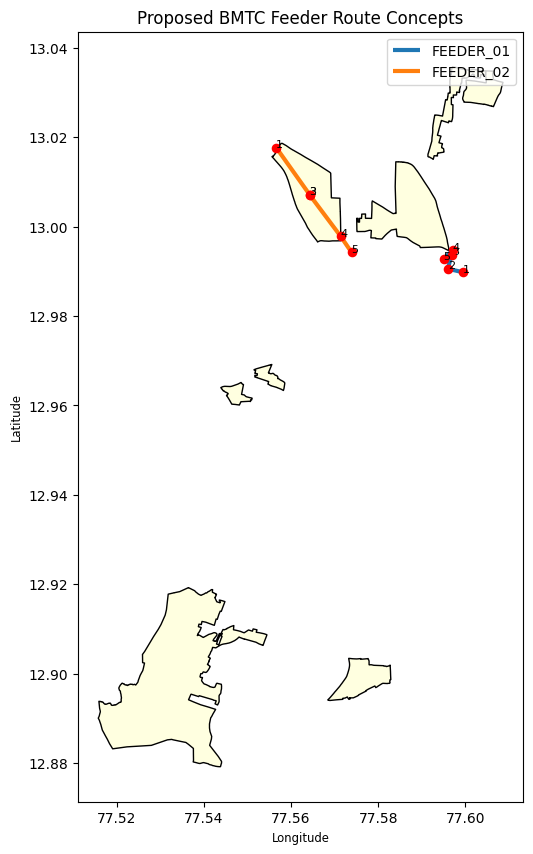

In [ ]:
# Create a map of the two feeder routes

wards_map = gpd.read_file(
    os.path.join(
        ANALYSIS_PATH,
        "ward_bus_coverage.geojson"
    )
)

wards_map = wards_map.to_crs("EPSG:4326")

# Ensure ward_id is explicitly compared as string column name and type matches target list
wards_map["ward_id_int"] = pd.to_numeric(wards_map["ward_id"], errors="coerce")
selected_ward_map_4326 = wards_map[
    wards_map["ward_id_int"].isin(TARGET_WARDS)
].copy()

fig, ax = plt.subplots(figsize=(12, 10))

selected_ward_map_4326.plot(
    ax=ax,
    color="lightyellow",
    edgecolor="black"
)

proposed_routes_geo.plot(
    ax=ax,
    column="proposed_route_id",
    linewidth=3,
    legend=True
)

# Plot all proposed stops.
for _, stop in proposed_stops.iterrows():
    ax.scatter(
        stop["longitude"],
        stop["latitude"],
        s=35,
        color="red",
        zorder=3
    )

    ax.annotate(
        str(stop["stop_sequence"]),
        (stop["longitude"], stop["latitude"]),
        fontsize=8
    )

ax.set_title("Proposed BMTC Feeder Route Concepts")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.show()

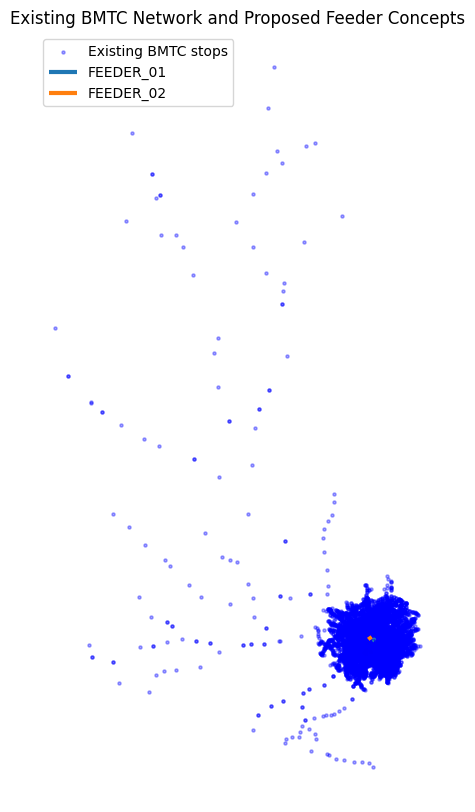

In [ ]:
# Create a map showing existing stops and proposed routes

fig, ax = plt.subplots(figsize=(13, 10))

selected_ward_map_4326.plot(
    ax=ax,
    color="lightyellow",
    edgecolor="black"
)

stops_geo.to_crs("EPSG:4326").plot(
    ax=ax,
    color="blue",
    markersize=5,
    alpha=0.35,
    label="Existing BMTC stops"
)

proposed_routes_geo.plot(
    ax=ax,
    column="proposed_route_id",
    linewidth=3,
    legend=True
)

ax.set_title("Existing BMTC Network and Proposed Feeder Concepts")
ax.set_axis_off()

plt.show()

In [ ]:
# Export all Phase 5 outputs

route_plan.to_csv(
    os.path.join(
        FEEDER_PATH,
        "proposed_feeder_routes.csv"
    ),
    index=False
)

print("Feeder-route proposals exported.")

Feeder-route proposals exported.


In [ ]:
proposed_stops.to_csv(
    os.path.join(
        FEEDER_PATH,
        "proposed_feeder_stop_sequence.csv"
    ),
    index=False
)

print("Stop sequence exported.")

Stop sequence exported.


In [ ]:
route_distances.to_csv(
    os.path.join(
        FEEDER_PATH,
        "proposed_route_distance_summary.csv"
    ),
    index=False
)

print("Route distance summary exported.")

Route distance summary exported.


In [ ]:
proposed_routes_geo.to_file(
    os.path.join(
        FEEDER_PATH,
        "proposed_feeder_routes.geojson"
    ),
    driver="GeoJSON"
)

print("Route GeoJSON exported.")

Route GeoJSON exported.


In [ ]:
route_connections_summary.to_csv(
    os.path.join(
        FEEDER_PATH,
        "existing_network_connections.csv"
    ),
    index=False
)

print("Existing network connections exported.")

Existing network connections exported.


In [ ]:
terminal_stops.to_csv(
    os.path.join(
        FEEDER_PATH,
        "selected_feeder_terminal_stops.csv"
    ),
    index=False
)

print("Terminal stop details exported.")

Terminal stop details exported.


In [ ]:
nearby_stops.to_csv(
    os.path.join(
        FEEDER_PATH,
        "nearby_stop_connectivity_summary.csv"
    ),
    index=False
)

print("Nearby stop connectivity summary exported.")

Nearby stop connectivity summary exported.


Quality checks and documentation

In [ ]:
# Verify the two proposed routes

print("Number of proposed routes:",
      route_plan["proposed_route_id"].nunique())

print("Route IDs:")
print(route_plan["proposed_route_id"].tolist())

print("\nTarget wards:")
display(
    route_plan[
        ["proposed_route_id", "target_ward_id", "target_ward_name"]
    ]
)

Number of proposed routes: 2
Route IDs:
['FEEDER_01', 'FEEDER_02']

Target wards:


,proposed_route_id,target_ward_id,target_ward_name
0,FEEDER_01,51,Old Guddadahalli
1,FEEDER_02,53,Rayapuram


In [ ]:
# Check whether all proposed stops exist in the GTFS data

known_stop_ids = set(stops["stop_id"].astype(str))

proposed_stops["stop_id_exists"] = (
    proposed_stops["stop_id"].astype(str).isin(known_stop_ids)
)

display(proposed_stops[
    ["proposed_route_id", "stop_id", "stop_name", "stop_id_exists"]
])

print(
    "All proposed stops exist:",
    proposed_stops["stop_id_exists"].all()
)

,proposed_route_id,stop_id,stop_name,stop_id_exists
0,FEEDER_01,21868,CSI Hospital,True
1,FEEDER_01,38454,Bhagwan Mahaveer Jain Hospital,True
2,FEEDER_01,21805,Cantonment Railway Station,True
3,FEEDER_01,32206,Cantonment Railway Station,True
4,FEEDER_01,22585,Vasantha Nagara,True
5,FEEDER_02,24016,Yeshawanthapura Bus Station,True
6,FEEDER_02,29383,Malleshwaram 15th Cross(8th Main),True
7,FEEDER_02,35424,Malleshwaram 15th Cross(8th Main),True
8,FEEDER_02,20988,Malleshwara Circle,True
9,FEEDER_02,20971,Link Road,True


All proposed stops exist: True


In [ ]:
# Check for duplicate stops within each route

duplicate_stop_check = (
    proposed_stops
    .groupby("proposed_route_id")["stop_id"]
    .apply(lambda x: x.duplicated().sum())
    .reset_index(name="duplicate_stop_count")
)

display(duplicate_stop_check)

,proposed_route_id,duplicate_stop_count
0,FEEDER_01,0
1,FEEDER_02,0


In [ ]:
# Create the Phase 5 quality report

quality_report = pd.DataFrame([
    {
        "check": "Exactly two proposed feeder routes",
        "result": route_plan["proposed_route_id"].nunique() == 2
    },
    {
        "check": "Both target wards selected",
        "result": set(route_plan["target_ward_id"]) == set(TARGET_WARDS)
    },
    {
        "check": "All proposed stops exist in GTFS",
        "result": proposed_stops["stop_id_exists"].all()
    },
    {
        "check": "No duplicate stops within routes",
        "result": duplicate_stop_check["duplicate_stop_count"].sum() == 0
    },
    {
        "check": "Route distance calculations completed",
        "result": len(route_distances) == 2
    },
    {
        "check": "Route geometries created",
        "result": len(proposed_routes_geo) == 2
    },
    {
        "check": "Existing network connections calculated",
        "result": len(route_connections_summary) == 2
    }
])

display(quality_report)

,check,result
0,Exactly two proposed feeder routes,True
1,Both target wards selected,True
2,All proposed stops exist in GTFS,True
3,No duplicate stops within routes,True
4,Route distance calculations completed,True
5,Route geometries created,True
6,Existing network connections calculated,True


In [ ]:
# Export the quality report

quality_report.to_csv(
    os.path.join(
        REPORT_PATH,
        "phase5_quality_report.csv"
    ),
    index=False
)

print("Quality report saved.")

Quality report saved.


In [ ]:
# Create the methodology report

methodology = pd.DataFrame([
    {
        "component": "Target ward selection",
        "method": "Selected Old Guddadahalli (Ward 51) and Rayapuram (Ward 53) from the Phase 4 high-priority candidate dataset."
    },
    {
        "component": "Nearby stop identification",
        "method": "Used existing GTFS stops within 2 km straight-line distance of the selected ward centroids."
    },
    {
        "component": "Network connectivity",
        "method": "Joined GTFS stop_times and trips tables to calculate distinct existing routes serving each stop."
    },
    {
        "component": "Terminal selection",
        "method": "Selected stops with high existing route connectivity, favouring separated terminal candidates."
    },
    {
        "component": "Intermediate stops",
        "method": "Selected existing GTFS stops near the straight-line corridor between the terminal stops."
    },
    {
        "component": "Route distance",
        "method": "Calculated the sum of straight-line distances between consecutive proposed stops."
    },
    {
        "component": "Limitations",
        "method": "Conceptual routes only. Road-network distance, passenger demand, ridership, walking access, traffic, service frequency and operational feasibility have not been verified."
    }
])

methodology.to_csv(
    os.path.join(
        REPORT_PATH,
        "phase5_methodology.csv"
    ),
    index=False
)

print("Methodology report saved.")

Methodology report saved.


In [ ]:
# Create the Phase 5 completion log

completion_log = pd.DataFrame([
    {
        "phase": "Phase 5",
        "task": "Selection of two underserved wards",
        "status": "Completed"
    },
    {
        "phase": "Phase 5",
        "task": "Nearby BMTC stop analysis",
        "status": "Completed"
    },
    {
        "phase": "Phase 5",
        "task": "Existing route connectivity analysis",
        "status": "Completed"
    },
    {
        "phase": "Phase 5",
        "task": "Two feeder route concepts",
        "status": "Completed"
    },
    {
        "phase": "Phase 5",
        "task": "Route distance calculation",
        "status": "Completed"
    },
    {
        "phase": "Phase 5",
        "task": "Route visualisation and GeoJSON export",
        "status": "Completed"
    },
    {
        "phase": "Phase 5",
        "task": "Quality validation and methodology documentation",
        "status": "Completed"
    }
])

completion_log.to_csv(
    os.path.join(
        REPORT_PATH,
        "phase5_completion_log.csv"
    ),
    index=False
)

print("Completion log saved.")

Completion log saved.


In [ ]:
# Verify all exported files

print("FEEDER ROUTE PLANNING FILES")
print("--------------------------------")

for file in sorted(os.listdir(FEEDER_PATH)):
    print(file)

print("\nPHASE 5 REPORT FILES")
print("--------------------------------")

for file in sorted(os.listdir(REPORT_PATH)):
    print(file)

FEEDER ROUTE PLANNING FILES
--------------------------------
existing_network_connections.csv
nearby_existing_bus_stops.csv
nearby_stop_connectivity_summary.csv
proposed_feeder_routes.csv
proposed_feeder_routes.geojson
proposed_feeder_stop_sequence.csv
proposed_route_distance_summary.csv
selected_feeder_terminal_stops.csv
selected_target_wards.csv

PHASE 5 REPORT FILES
--------------------------------
phase5_completion_log.csv
phase5_methodology.csv
phase5_quality_report.csv


In [ ]:
# Display the final feeder-route comparison

final_summary = route_plan.merge(
    route_distances,
    on=["proposed_route_id", "target_ward_id"],
    how="left"
)

display(
    final_summary[
        [
            "proposed_route_id",
            "target_ward_name",
            "proposed_start_stop_name",
            "proposed_end_stop_name",
            "number_of_existing_routes_connected",
            "number_of_stops",
            "approximate_straight_line_distance_km"
        ]
    ]
)

,proposed_route_id,target_ward_name,proposed_start_stop_name,proposed_end_stop_name,number_of_existing_routes_connected,number_of_stops,approximate_straight_line_distance_km
0,FEEDER_01,Old Guddadahalli,CSI Hospital,Vasantha Nagara,320,5,1.174
1,FEEDER_02,Rayapuram,Yeshawanthapura Bus Station,Link Road,396,5,3.214


In [ ]:
# Final Phase 5 validation

print("PHASE 5 FINAL VALIDATION")
print("=" * 40)

print("Proposed routes:",
      route_plan["proposed_route_id"].nunique())

print("Target wards:",
      route_plan["target_ward_name"].tolist())

print("All proposed stops verified:",
      proposed_stops["stop_id_exists"].all())

print("All quality checks passed:",
      quality_report["result"].all())

print("Route geometries:",
      len(proposed_routes_geo))

print("\nPhase 5 outputs are ready for review.")


PHASE 5 FINAL VALIDATION
Proposed routes: 2
Target wards: ['Old Guddadahalli', 'Rayapuram']
All proposed stops verified: True
All quality checks passed: True
Route geometries: 2

Phase 5 outputs are ready for review.


In [ ]:
# Phase 5 – Final

# Verify that all Phase 5 files exist

import os

print("FEEDER ROUTE OUTPUTS")
for file in sorted(os.listdir(FEEDER_PATH)):
    print("✓", file)

print("\nPHASE 5 REPORTS")
for file in sorted(os.listdir(REPORT_PATH)):
    print("✓", file)


FEEDER ROUTE OUTPUTS
✓ existing_network_connections.csv
✓ nearby_existing_bus_stops.csv
✓ nearby_stop_connectivity_summary.csv
✓ proposed_feeder_routes.csv
✓ proposed_feeder_routes.geojson
✓ proposed_feeder_stop_sequence.csv
✓ proposed_route_distance_summary.csv
✓ selected_feeder_terminal_stops.csv
✓ selected_target_wards.csv

PHASE 5 REPORTS
✓ phase5_completion_log.csv
✓ phase5_methodology.csv
✓ phase5_quality_report.csv


In [ ]:
# Save the final route comparison

final_summary.to_csv(
    os.path.join(
        REPORT_PATH,
        "final_feeder_route_comparison.csv"
    ),
    index=False
)

print("Final route comparison saved.")

Final route comparison saved.
